# Análisis de Biomasa Residual Agrícola en Argentina

**Objetivo**: Estimar la biomasa residual generada por los principales cultivos extensivos a nivel departamental, integrando dos fuentes oficiales: la Bolsa de Cereales de Córdoba (CBA) y las Estimaciones Agrícolas del Ministerio de Agricultura, Ganadería y Pesca de la Nación (MAGYP), y **convertirla en energía eléctrica (gasificador APL PP30) y en valor económico (ARS)** bajo el régimen de generación distribuida (Ley 27.424).

**Estructura narrativa del análisis**:

| Fase | Descripción |
|------|-------------|
| **1. Exploración** | Ingesta de fuentes, diagnóstico de estructura, dominios y calidad. |
| **2. Conclusiones y acciones** | Síntesis de hallazgos y plan de acciones a implementar. |
| **3. Desarrollo** | Implementación de las acciones: normalización, taxonomía, reconciliación, biomasa. |
| **4. Pruebas y mediciones** | Verificación de invariantes y cuantificación del impacto. |
| **5. Conversión a energía** | Residuo recuperable → masa alimentada al gasificador → kWh. |
| **6. Valorización económica** | kWh → ahorro por autoconsumo + crédito por inyección (ARS). |
| **7. Persistencia y síntesis** | Artefactos, hallazgos y limitaciones. |

> **Nota de unidades**: todas las magnitudes de las Fases 5 y 6 se expresan **por año**, como promedio del período de referencia (últimas 5 campañas completas). Sumar varias campañas no tiene interpretación física (ver hallazgo H10).

In [1]:
import json
import re
import sys
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pytest

# Permite importar el paquete `etl` desde notebooks/ (raíz del repo en sys.path).
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from etl.extractors.io_utils import RAW_STEM_CBA, RAW_STEM_MAGYP, find_latest_raw

DATA = ROOT / "data"

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Fase 1 — Exploración

En esta fase se caracteriza la estructura, los dominios y la calidad de las dos fuentes primarias sin aplicar transformaciones. El objetivo es producir evidencia suficiente para decidir qué acciones de limpieza y reconciliación son necesarias.

## 1.1 Ingesta de fuentes primarias

Se cargan ambos datasets en su forma cruda. Los extractores versionan los archivos como `YYYYMMDDHHMMSS_<fuente>.csv`; se usa `find_latest_raw` para tomar siempre **el artefacto más reciente** (antes el notebook leía rutas fijas y podía analizar datos viejos mientras el ETL usaba otros).

El dataset de la Bolsa de Cereales de Buenos Aires fue descartado por utilizar la zonificación PAS en lugar de la división administrativa departamental, incompatible con la granularidad requerida.

In [2]:
path_cba = find_latest_raw(DATA / "raw", RAW_STEM_CBA)
path_magyp = find_latest_raw(DATA / "raw", RAW_STEM_MAGYP)
print("CBA:  ", path_cba.name)
print("MAGYP:", path_magyp.name)

df_bolsa_cereales_cba = pd.read_csv(path_cba)
df_estimaciones_agricolas = pd.read_csv(path_magyp, encoding="utf-8-sig")
df_IC = pd.read_csv(DATA / "reference" / "ic_fr.csv")

CBA:   20261004161219_datos_bolsa_granos_cba.csv
MAGYP: 20261004161118_datos_estimaciones.csv


## 1.2 Diagnóstico de estructura

Se inspecciona la forma, tipos y cobertura de nulos de cada fuente. Esto permite identificar problemas de calidad antes de cualquier transformación.

In [3]:
print("================ BOLSA DE CEREALES CBA ================")
print(df_bolsa_cereales_cba.info())
print("\n================ MAGYP ESTIMACIONES ================")
print(df_estimaciones_agricolas.info())

================ BOLSA DE CEREALES CBA ================
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4064 entries, 0 to 4063
Data columns (total 10 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   PROVINCIA                        4064 non-null   object 
 1   DEPARTAMENTO                     4064 non-null   object 
 2   CULTIVO                          4064 non-null   object 
 3   CAMPAÑA                          4064 non-null   object 
 4   SEMBRADAS                        4064 non-null   float64
 5   COSECHADAS                       4064 non-null   float64
 6   RENDIMIENTO                      3820 non-null   float64
 7   RENDIMIENTO GRANO LIMPIO Y SECO  197 non-null    float64
 8   PRODUCCIÓN                       3820 non-null   float64
 9   PRODUCCIÓN GRANO LIMPIO Y SECO   197 non-null    float64
dtypes: float64(6), object(4)
memory usage: 317.6+ KB
None

================ MAGYP ESTIMACION

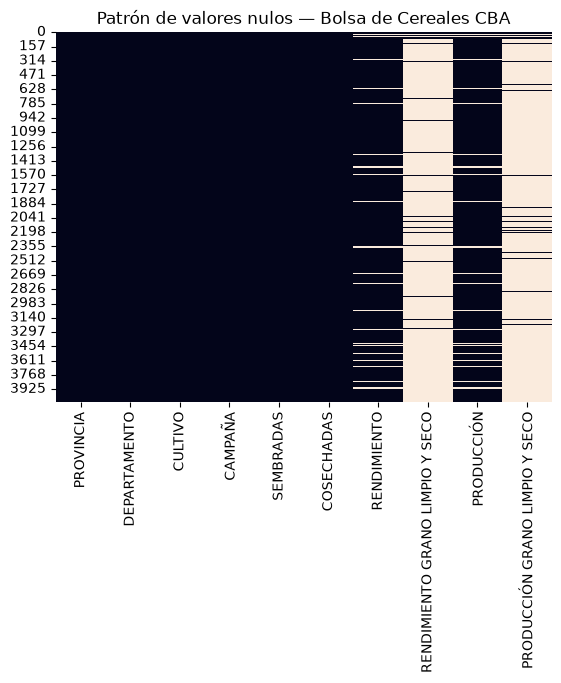

In [4]:
sns.heatmap(df_bolsa_cereales_cba.isnull(), cbar=False)
plt.title("Patrón de valores nulos — Bolsa de Cereales CBA")
plt.show()

## 1.3 Exploración de dominios categóricos

Se listan los valores únicos de las columnas `Cultivo`, `Provincia` y `Departamento` en cada fuente, para detectar variabilidad ortográfica, abreviaturas y agregados (`X total`).

In [5]:
print("Cultivos crudos CBA ({} únicos):".format(df_bolsa_cereales_cba["CULTIVO"].nunique()))
print(sorted(df_bolsa_cereales_cba["CULTIVO"].unique()))

print("\nProvincias CBA:", sorted(df_bolsa_cereales_cba["PROVINCIA"].unique()))

deptos_cba = sorted(df_bolsa_cereales_cba["DEPARTAMENTO"].unique())
print(f"\nDepartamentos CBA: {len(deptos_cba)} únicos. Muestra:")
print(deptos_cba[:10], "...")

Cultivos crudos CBA (10 únicos):
['ALFALFA', 'GARBANZO', 'GIRASOL', 'MAIZ', 'MANI', 'SOJA', 'SORGO', 'SORGO ', 'TRIGO', 'TRIGO CANDEAL']

Provincias CBA: ['Buenos Aires', 'Catamarca', 'Córdoba', 'La Pampa', 'San Luis', 'Santiago del Estero', 'Tucumán']

Departamentos CBA: 124 únicos. Muestra:
['25 DE MAYO', '9 DE JULIO', 'ADOLFO ALSINA', 'AGUIRRE', 'ALBERDI', 'AMBATO', 'ATREUCO', 'AVELLANEDA', 'AYACUCHO', 'BANDA'] ...


In [6]:
print("Cultivos crudos MAGYP ({} únicos):".format(df_estimaciones_agricolas["Cultivo"].nunique()))
print(sorted(df_estimaciones_agricolas["Cultivo"].unique()))

print("\nProvincias MAGYP:", df_estimaciones_agricolas["Provincia"].nunique(), "únicas")
print("Departamentos MAGYP:", df_estimaciones_agricolas["Departamento"].nunique(), "únicos")

Cultivos crudos MAGYP (41 únicos):
['Ajo', 'Algodón', 'Alpiste', 'Arroz', 'Arveja', 'Avena', 'Banana', 'Caña de azúcar', 'Cebada cervecera', 'Cebada forrajera', 'Cebada total', 'Cebolla total', 'Centeno', 'Colza', 'Cártamo', 'Garbanzo', 'Girasol', 'Jojoba', 'Lenteja', 'Limón', 'Lino', 'Mandarina', 'Maní', 'Maíz', 'Mijo', 'Naranja', 'Papa total', 'Pomelo', 'Poroto alubia', 'Poroto negro', 'Poroto otros', 'Poroto total', 'Soja 1ra', 'Soja 2da', 'Soja total', 'Sorgo', 'Trigo candeal', 'Trigo total', 'Tung', 'Té', 'Yerba mate']

Provincias MAGYP: 23 únicas
Departamentos MAGYP: 410 únicos


## 1.4 Diagnóstico de solapamiento entre fuentes

Se cuantifica cuántas claves naturales `(Provincia, Departamento, Campaña, Cultivo)` estarán potencialmente cubiertas por ambas fuentes. Esto determina si el problema de doble conteo es relevante.

In [7]:
prov_cba = set(df_bolsa_cereales_cba["PROVINCIA"].str.strip().str.lower())
prov_magyp = set(df_estimaciones_agricolas["Provincia"].str.strip().str.lower())

print(f"Provincias CBA: {len(prov_cba)} | MAGYP: {len(prov_magyp)}")
print(f"Intersección de provincias: {sorted(prov_cba & prov_magyp)}")

Provincias CBA: 7 | MAGYP: 23
Intersección de provincias: ['buenos aires', 'catamarca', 'la pampa', 'san luis', 'santiago del estero']


## 1.5 Diagnóstico de duplicados y faltantes

Antes de transformar se verifican tres problemas detectados en la revisión del ETL:

- **Filas replicadas en CBA**: el extractor combina tres hojas del Excel con un *merge outer*. Si la hoja de producción trae más de una fila por clave (variantes de "grano limpio y seco"), el merge genera un **producto cartesiano** que repite la misma superficie y producción 2 o 4 veces. Al agrupar con `sum` la producción quedaba multiplicada.
- **Valores `SD` (sin dato) en MAGYP**: se coercionan a `NaN`, pero `groupby().sum()` convierte un grupo íntegramente `NaN` en **0**: un faltante pasaba a ser "producción cero".
- **Rango temporal**: MAGYP cubre desde 1969/70 y la última campaña puede estar incompleta.

In [8]:
key_cba = ["PROVINCIA", "DEPARTAMENTO", "CULTIVO", "CAMPAÑA"]
core_cba = ["SEMBRADAS", "COSECHADAS", "RENDIMIENTO", "PRODUCCIÓN"]
dup_mask = df_bolsa_cereales_cba.duplicated(key_cba + core_cba, keep=False)
print(f"CBA — filas con clave + valores núcleo repetidos: {dup_mask.sum()}")
display(df_bolsa_cereales_cba[dup_mask].sort_values(key_cba).head(8))

sd = (df_estimaciones_agricolas[["Sup. Sembrada", "Sup. Cosechada", "Producción", "Rendimiento"]] == "SD").sum()
print("\nMAGYP — celdas 'SD' (sin dato) por columna:")
print(sd)

camp_counts = df_estimaciones_agricolas["Campaña"].value_counts().sort_index()
print(f"\nMAGYP — campañas: {camp_counts.index.min()} a {camp_counts.index.max()} ({len(camp_counts)} campañas)")
print("Registros por campaña (últimas 8):")
print(camp_counts.tail(8))

CBA — filas con clave + valores núcleo repetidos: 0


,PROVINCIA,DEPARTAMENTO,CULTIVO,CAMPAÑA,SEMBRADAS,COSECHADAS,RENDIMIENTO,RENDIMIENTO GRANO LIMPIO Y SECO,PRODUCCIÓN,PRODUCCIÓN GRANO LIMPIO Y SECO



MAGYP — celdas 'SD' (sin dato) por columna:
Sup. Sembrada     3201
Sup. Cosechada    3214
Producción          17
Rendimiento       3218
dtype: int64

MAGYP — campañas: 1969/70 a 2025/26 (57 campañas)
Registros por campaña (últimas 8):
Campaña
2018/19    2446
2019/20    2561
2020/21    2740
2021/22    2987
2022/23    3004
2023/24    3072
2024/25    3161
2025/26    1724
Name: count, dtype: int64


## 1.6 Conclusiones de la exploración

De los diagnósticos anteriores se derivan los siguientes hallazgos:

**H1 — Cobertura geográfica asimétrica**. MAGYP cubre 23 provincias; CBA cubre 7. Existe intersección parcial entre ambas, lo que genera riesgo de doble conteo al integrar sin política de reconciliación.

**H2 — Inconsistencia léxica en cultivos**. CBA usa mayúsculas (`MAIZ`, `SOJA`, `SORGO `); MAGYP usa capitalización tipo título (`Maíz`, `Soja`, `Sorgo`). Además, CBA presenta espacios residuales (`SORGO `) y MAGYP utiliza sufijos `total` para agregados.

**H3 — Estructura agregado/componente**. MAGYP reporta simultáneamente registros agregados (`Soja total`, `Cebada total`) y sus componentes (`Soja 1ra`, `Soja 2da`, `Cebada cervecera`, `Cebada forrajera`). Sumar sin resolver genera doble conteo.

**H4 — Inconsistencia en nomenclatura de departamentos**. CBA presenta abreviaturas (`GRAL PEDERNERA`, `J.B.ALBERDI`) y variabilidad en puntuación (`LEANDRO N ALEM`, `LEANDRO N. ALEM`), mientras que MAGYP usa nombres completos (`GENERAL PEDERNERA`, `JUAN B. ALBERDI`).

**H5 — Columnas con cobertura marginal**. CBA tiene `RENDIMIENTO GRANO LIMPIO Y SECO` y `PRODUCCIÓN GRANO LIMPIO Y SECO` con cobertura ~5% (215/4094). Representan sub-categorías específicas, no la variable principal.

**H6 — Tipo de datos incorrecto en MAGYP**. Las columnas numéricas (`Sup. Sembrada`, `Sup. Cosechada`, `Producción`, `Rendimiento`) están codificadas como `str`.

**H7 — Índices de cosecha no cubren todos los cultivos**. La tabla de referencia IC tiene 17 entradas; MAGYP reporta 33 cultivos canónicos. Los cultivos sin IC documentado no pueden procesarse.

**H8 — Filas replicadas en CBA**. El merge outer del extractor genera un producto cartesiano en las claves con más de una variante de "grano limpio y seco": la misma producción aparece 4 veces y el `sum` posterior la cuadruplica.

**H9 — Faltantes convertidos en cero**. `groupby().sum()` devuelve 0 para grupos íntegramente `NaN` (celdas `SD` de MAGYP).

**H10 — Serie histórica de 57 campañas**. Sumar residuo (o kWh, o ARS) sobre todas las campañas mezcla 1969 con 2025 y no representa ninguna magnitud física. El potencial energético es un **flujo anual**. Además la última campaña (2025/26) tiene menos de la mitad de los registros de las anteriores: está incompleta.

**H11 — IC en base seca vs. producción a humedad comercial**. El índice de cosecha se define sobre materia seca; la producción se reporta a humedad comercial (granos, 11–15 %) o **en fresco** (papa ≈ 80 % de agua, ajo ≈ 65 %). Aplicar FR directamente a la producción sobreestima el residuo (≈ +15 % en granos, ×3–5 en papa/ajo).

**H12 — No todo el rastrojo es recolectable**. Retirar el 100 % del residuo del lote es agronómicamente inviable (erosión, pérdida de materia orgánica). El potencial energético debe calcularse sobre el residuo **recuperable**.

# Fase 2 — Conclusiones y plan de acciones

Las conclusiones de la Fase 1 derivan en un conjunto explícito de acciones a implementar en la Fase 3. Cada acción responde a uno o más hallazgos.

| Acción | Hallazgo que resuelve | Descripción |
|--------|----------------------|-------------|
| **A1** | H2 | Normalización léxica determinística de strings (NFKD, ASCII, lowercase, colapso de espacios). |
| **A2** | H3 | Definición de taxonomía canónica con marca de agregado y componentes declarados. |
| **A3** | H4 | Normalización geográfica con diccionario de abreviaturas y alias por provincia. |
| **A4** | H3 | Resolución de coexistencia agregado/componente por clave natural (prevalece agregado). |
| **A5** | H1 | Política de reconciliación multi-fuente por mayor producción declarada. |
| **A6** | H5 | Eliminación justificada de columnas de cobertura marginal en CBA. |
| **A7** | H6 | Conversión de tipos numéricos con reporte de coerción. |
| **A8** | H7 | Manejo explícito de cultivos sin IC mediante flags de validez (no `dropna`). |
| **A9** | H8 | Deduplicación de filas replicadas en CBA sobre clave + columnas núcleo. |
| **A10** | H9 | Agregación con `sum(min_count=1)`: un grupo sin datos queda `NaN`, no 0. |
| **A11** | H10 | Período de referencia: promedio anual de las últimas 5 campañas **completas**. |
| **A12** | H11 | Biomasa en base seca: `Residuo = Producción × MS × FR`. |
| **A13** | H12 | Fracción recuperable del residuo (50 % por defecto) antes de convertir a energía. |

**Política de reconciliación multi-fuente (POL-SOURCE-001)**: en claves cubiertas simultáneamente por CBA y MAGYP, prevalece el registro con mayor producción declarada, fundado en la naturaleza jurídica de los datos declarados ante AFIP en el marco del SISA (Resolución General Conjunta MAGyP y AFIP 5236). Los registros descartados se preservan en datasets de auditoría.

**Desempate en la reconciliación**: si ambas fuentes declaran exactamente la misma producción, prevalece MAGYP (fuente oficial). Sin este criterio el resultado dependía del orden de concatenación.

# Fase 3 — Desarrollo de acciones

Implementación de las acciones A1–A8 definidas en la Fase 2.

## 3.1 A1 — Normalización léxica

Función idempotente: NFKD → ASCII → colapso de whitespace → lowercase → strip.

In [9]:
def clean_str(s: str) -> str:
    """Normaliza strings para matching determinístico entre fuentes."""
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFKD", s)
    s = s.encode("ascii", "ignore").decode("ascii")
    s = re.sub(r"\s+", " ", s)
    return s.strip().lower()

## 3.2 A3 — Normalización geográfica

Pipeline en cuatro etapas: normalización léxica, remoción de puntos, expansión de abreviaturas, resolución de alias por `(provincia, departamento)`.

In [10]:
def strip_periods(s: str) -> str:
    if not isinstance(s, str):
        return s
    return re.sub(r"\s+", " ", s.replace(".", " ")).strip()


ABBREV_SAFE = {
    "gral": "general", "pte": "presidente", "gob": "gobernador",
    "dr": "doctor", "dra": "doctora", "cnl": "coronel",
    "tte": "teniente", "sgt": "sargento", "cap": "capitan",
}


def expand_abbrevs(s: str, mapping: dict = ABBREV_SAFE) -> str:
    if not isinstance(s, str):
        return s
    return " ".join(mapping.get(tok, tok) for tok in s.split(" "))


DEPT_ALIASES = {
    ("tucuman",             "j b alberdi"):  "juan b alberdi",
    ("santiago del estero", "j f ibarra"):   "juan felipe ibarra",
}


def resolve_dept_alias(provincia: str, dept: str, aliases: dict = DEPT_ALIASES) -> str:
    return aliases.get((provincia, dept), dept)


def normalize_geo(
    df: pd.DataFrame,
    prov_col: str = "Provincia",
    dept_col: str = "Departamento",
    aliases: dict = DEPT_ALIASES,
) -> pd.DataFrame:
    df = df.copy()
    df[prov_col] = df[prov_col].apply(clean_str)
    df[dept_col] = (
        df[dept_col].apply(clean_str).apply(strip_periods).apply(expand_abbrevs)
    )
    df[dept_col] = [
        resolve_dept_alias(p, d, aliases) for p, d in zip(df[prov_col], df[dept_col])
    ]
    return df


def flag_invalid_geo(df: pd.DataFrame, dept_col: str = "Departamento") -> pd.DataFrame:
    df = df.copy()
    df["_dept_valido"] = ~df[dept_col].isin({"sin definir", "", "na", "n/a"})
    return df

## 3.3 A2 — Taxonomía canónica de cultivos

Tabla declarativa que mapea nombres raw a nombres canónicos, con marca de agregado y componentes. Reglas:

- Nombres compuestos (`caña de azúcar`, `yerba mate`) no se colapsan.
- Cultivos biológicamente distintos (`trigo candeal` vs `trigo`) se preservan separados.
- Nombres base canónicos (`soja`, `trigo`, `cebada`, `poroto`, `papa`, `cebolla`) se incluyen explícitamente.
- Falla bloqueante (`fail-fast`) ante entradas no mapeadas.

In [11]:
CROP_TAXONOMY = {
    # Familia soja
    "soja":       {"canonical": "soja",   "is_aggregate": False},
    "soja 1ra":   {"canonical": "soja",   "is_aggregate": False},
    "soja 2da":   {"canonical": "soja",   "is_aggregate": False},
    "soja total": {"canonical": "soja",   "is_aggregate": True},
    # Familia cebada
    "cebada":           {"canonical": "cebada", "is_aggregate": False},
    "cebada cervecera": {"canonical": "cebada", "is_aggregate": False},
    "cebada forrajera": {"canonical": "cebada", "is_aggregate": False},
    "cebada total":     {"canonical": "cebada", "is_aggregate": True},
    # Familia poroto
    "poroto":        {"canonical": "poroto", "is_aggregate": False},
    "poroto alubia": {"canonical": "poroto", "is_aggregate": False},
    "poroto negro":  {"canonical": "poroto", "is_aggregate": False},
    "poroto otros":  {"canonical": "poroto", "is_aggregate": False},
    "poroto total":  {"canonical": "poroto", "is_aggregate": True},
    # Totales sin breakdown
    "trigo":         {"canonical": "trigo",   "is_aggregate": False},
    "trigo total":   {"canonical": "trigo",   "is_aggregate": True},
    "papa":          {"canonical": "papa",    "is_aggregate": False},
    "papa total":    {"canonical": "papa",    "is_aggregate": True},
    "cebolla":       {"canonical": "cebolla", "is_aggregate": False},
    "cebolla total": {"canonical": "cebolla", "is_aggregate": True},
    # Compuestos / biológicamente distintos
    "trigo candeal":  {"canonical": "trigo candeal",  "is_aggregate": False},
    "cana de azucar": {"canonical": "cana de azucar", "is_aggregate": False},
    "yerba mate":     {"canonical": "yerba mate",     "is_aggregate": False},
    # Cultivos simples
    "alfalfa":   {"canonical": "alfalfa",  "is_aggregate": False},  # forrajera CBA, sin IC
    "ajo":       {"canonical": "ajo",      "is_aggregate": False},
    "algodon":   {"canonical": "algodon",  "is_aggregate": False},
    "alpiste":   {"canonical": "alpiste",  "is_aggregate": False},
    "arroz":     {"canonical": "arroz",    "is_aggregate": False},
    "arveja":    {"canonical": "arveja",   "is_aggregate": False},
    "avena":     {"canonical": "avena",    "is_aggregate": False},
    "banana":    {"canonical": "banana",   "is_aggregate": False},
    "cartamo":   {"canonical": "cartamo",  "is_aggregate": False},
    "centeno":   {"canonical": "centeno",  "is_aggregate": False},
    "colza":     {"canonical": "colza",    "is_aggregate": False},
    "garbanzo":  {"canonical": "garbanzo", "is_aggregate": False},
    "girasol":   {"canonical": "girasol",  "is_aggregate": False},
    "jojoba":    {"canonical": "jojoba",   "is_aggregate": False},
    "lenteja":   {"canonical": "lenteja",  "is_aggregate": False},
    "limon":     {"canonical": "limon",    "is_aggregate": False},
    "lino":      {"canonical": "lino",     "is_aggregate": False},
    "maiz":      {"canonical": "maiz",     "is_aggregate": False},
    "mandarina": {"canonical": "mandarina","is_aggregate": False},
    "mani":      {"canonical": "mani",     "is_aggregate": False},
    "mijo":      {"canonical": "mijo",     "is_aggregate": False},
    "naranja":   {"canonical": "naranja",  "is_aggregate": False},
    "pomelo":    {"canonical": "pomelo",   "is_aggregate": False},
    "sorgo":     {"canonical": "sorgo",    "is_aggregate": False},
    "te":        {"canonical": "te",       "is_aggregate": False},
    "tung":      {"canonical": "tung",     "is_aggregate": False},
}

## 3.4 A4 — Resolución de agregados vs componentes

Función pura que, por clave natural `(Campaña, Provincia, Departamento, cultivo_canónico)`, conserva únicamente los registros agregados si coexisten con componentes. Preserva trazabilidad en `_source_cultivo`.

In [12]:
def resolve_crops(
    df: pd.DataFrame,
    taxonomy: dict,
    raw_col: str = "Cultivo",
    keys: tuple = ("Campaña", "Provincia", "Departamento"),
) -> pd.DataFrame:
    df = df.copy()
    unmapped = sorted(set(df[raw_col].unique()) - set(taxonomy.keys()))
    if unmapped:
        raise ValueError(
            f"Cultivos sin mapeo en CROP_TAXONOMY: {unmapped}. "
            "Agregar explícitamente antes de continuar."
        )
    meta = df[raw_col].map(taxonomy)
    df["_canonical"]    = meta.map(lambda x: x["canonical"])
    df["_is_aggregate"] = meta.map(lambda x: x["is_aggregate"])

    gkey = list(keys) + ["_canonical"]
    df["_has_aggregate"] = (
        df.groupby(gkey, dropna=False)["_is_aggregate"].transform("any")
    )
    keep_mask = (~df["_has_aggregate"]) | (df["_is_aggregate"])
    resolved = df.loc[keep_mask].copy()
    resolved["_source_cultivo"] = resolved[raw_col]
    resolved = resolved.drop(columns=[raw_col, "_is_aggregate", "_has_aggregate"])
    resolved = resolved.rename(columns={"_canonical": "Cultivo"})
    return resolved.reset_index(drop=True)

## 3.5 A6 + A9 — Limpieza CBA

Se descartan las columnas de grano limpio y seco por cobertura marginal (~5 %). **Después** de descartarlas, las filas que el merge cartesiano había replicado quedan idénticas en clave + columnas núcleo y se eliminan (A9). Finalmente se descartan sólo las filas sin superficie cosechada o sin producción (en lugar de un `dropna` global que eliminaría filas por nulos en columnas accesorias).

In [13]:
df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba.drop(
    columns=["RENDIMIENTO GRANO LIMPIO Y SECO", "PRODUCCIÓN GRANO LIMPIO Y SECO"]
)
n_antes = len(df_bolsa_cereales_cba_cleaned)
df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba_cleaned.drop_duplicates(
    subset=key_cba + core_cba
)
print(f"Filas replicadas eliminadas (A9): {n_antes - len(df_bolsa_cereales_cba_cleaned)}")
df_bolsa_cereales_cba_cleaned = df_bolsa_cereales_cba_cleaned.dropna(subset=["COSECHADAS", "PRODUCCIÓN"])
df_bolsa_cereales_cba_cleaned.info()

Filas replicadas eliminadas (A9): 0
<class 'pandas.core.frame.DataFrame'>
Index: 3820 entries, 0 to 4063
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PROVINCIA     3820 non-null   object 
 1   DEPARTAMENTO  3820 non-null   object 
 2   CULTIVO       3820 non-null   object 
 3   CAMPAÑA       3820 non-null   object 
 4   SEMBRADAS     3820 non-null   float64
 5   COSECHADAS    3820 non-null   float64
 6   RENDIMIENTO   3820 non-null   float64
 7   PRODUCCIÓN    3820 non-null   float64
dtypes: float64(4), object(4)
memory usage: 268.6+ KB


## 3.6 Aplicación del pipeline a CBA

Se aplican A1 (léxica), A3 (geográfica), A4 (resolución de cultivos). Se descarta `_dept_valido` (todos válidos en CBA).

In [14]:
df_cba = df_bolsa_cereales_cba_cleaned.rename(columns={
    "PROVINCIA": "Provincia", "DEPARTAMENTO": "Departamento",
    "CULTIVO": "Cultivo", "CAMPAÑA": "Campaña",
})
df_cba["Cultivo"] = df_cba["Cultivo"].apply(clean_str)
df_cba = normalize_geo(df_cba)
df_cba = flag_invalid_geo(df_cba)
df_cba_resolved = resolve_crops(df_cba, CROP_TAXONOMY)
df_cba_resolved = df_cba_resolved.drop(columns=["_dept_valido"])

print("Cultivos canónicos CBA:", sorted(df_cba_resolved["Cultivo"].unique()))
print(f"Registros: {len(df_cba_resolved):,}")

Cultivos canónicos CBA: ['garbanzo', 'girasol', 'maiz', 'mani', 'soja', 'sorgo', 'trigo', 'trigo candeal']
Registros: 3,820


## 3.7 Aplicación del pipeline a MAGYP

In [15]:
df_magyp = df_estimaciones_agricolas.copy()
df_magyp["Cultivo"] = df_magyp["Cultivo"].apply(clean_str)
df_magyp = normalize_geo(df_magyp)
df_magyp = flag_invalid_geo(df_magyp)
df_est_resolved = resolve_crops(df_magyp, CROP_TAXONOMY)
df_est_resolved = df_est_resolved.drop(columns=["_dept_valido"])

print("Cultivos canónicos MAGYP:", sorted(df_est_resolved["Cultivo"].unique()))
print(f"Registros: {len(df_est_resolved):,}")

Cultivos canónicos MAGYP: ['ajo', 'algodon', 'alpiste', 'arroz', 'arveja', 'avena', 'banana', 'cana de azucar', 'cartamo', 'cebada', 'cebolla', 'centeno', 'colza', 'garbanzo', 'girasol', 'jojoba', 'lenteja', 'limon', 'lino', 'maiz', 'mandarina', 'mani', 'mijo', 'naranja', 'papa', 'pomelo', 'poroto', 'soja', 'sorgo', 'te', 'trigo', 'trigo candeal', 'tung', 'yerba mate']
Registros: 150,324


## 3.8 A7 — Conversión de tipos numéricos en MAGYP

Se aplica `pd.to_numeric` con `errors='coerce'` y se reporta el conteo de valores coercidos a NaN.

In [16]:
cols_num = ["Sup. Sembrada", "Sup. Cosechada", "Producción", "Rendimiento"]
report_coercion = {}
for c in cols_num:
    before = df_est_resolved[c].notna().sum()
    df_est_resolved[c] = pd.to_numeric(df_est_resolved[c], errors="coerce")
    after = df_est_resolved[c].notna().sum()
    report_coercion[c] = {
        "no_nulos_antes": int(before),
        "no_nulos_despues": int(after),
        "coercidos_a_NaN": int(before - after),
    }
pd.DataFrame(report_coercion).T

,no_nulos_antes,no_nulos_despues,coercidos_a_NaN
Sup. Sembrada,150324,147123,3201
Sup. Cosechada,150324,147110,3214
Producción,150324,150310,14
Rendimiento,150324,147109,3215


## 3.9 Agrupación por clave natural y normalización de esquema (A10)

Se agrupa cada fuente por `(Campaña, Provincia, Departamento, Cultivo)` sumando superficie cosechada y producción, y recalculando el rendimiento como cociente. Se usa `sum(min_count=1)` para que un grupo sin ningún dato válido quede `NaN` (y no 0). El rendimiento se deja `NaN` cuando la superficie cosechada es 0. Se agrega `fuente` para trazabilidad.

In [17]:
GROUP = ["Campaña", "Provincia", "Departamento", "Cultivo"]
CANON = ["Provincia", "Departamento", "Campaña", "Cultivo",
         "Superficie (Ha)", "Produccion (Tn)", "Rendimiento (Tn/Ha)"]


def agrupar(df, sup_col, prod_col, fuente):
    g = df.groupby(GROUP, as_index=False)[[sup_col, prod_col]].sum(min_count=1)
    g = g.rename(columns={sup_col: "Superficie (Ha)", prod_col: "Produccion (Tn)"})
    g["Rendimiento (Tn/Ha)"] = (g["Produccion (Tn)"] / g["Superficie (Ha)"]).where(g["Superficie (Ha)"] > 0)
    g = g[CANON].copy()
    g["fuente"] = fuente
    return g


df_est_norm = agrupar(df_est_resolved, "Sup. Cosechada", "Producción", "magyp_estimaciones")
df_cba_norm = agrupar(df_cba_resolved, "COSECHADAS", "PRODUCCIÓN", "bolsa_cereales_cba")

print(f"MAGYP agrupado: {df_est_norm.shape}  (producción NaN: {df_est_norm['Produccion (Tn)'].isna().sum()})")
print(f"CBA agrupado:   {df_cba_norm.shape}")

MAGYP agrupado: (147582, 8)  (producción NaN: 14)
CBA agrupado:   (3820, 8)


## 3.10 A5 — Reconciliación multi-fuente por mayor producción declarada

**POL-SOURCE-001**: en claves naturales cubiertas simultáneamente por ambas fuentes, prevalece el registro con mayor producción declarada. Fundamento: la información productiva declarada ante AFIP (SISA, RG Conjunta MAGyP-AFIP 5236) tiene carácter de declaración jurada y condiciona el tratamiento fiscal del productor (retenciones IVA y Ganancias). Cuando dos fuentes divergen, la política conservadora consiste en preservar la mayor magnitud reportada, minimizando subrepresentación del potencial de biomasa residual.

Los registros descartados se preservan en datasets de auditoría.

In [18]:
KEY = ["Provincia", "Departamento", "Campaña", "Cultivo"]
df_all = pd.concat([df_cba_norm, df_est_norm], ignore_index=True)

# Diagnóstico de cobertura previo a la reconciliación
coverage = (
    df_all.groupby(KEY)["fuente"].nunique().value_counts()
    .rename_axis("n_fuentes").to_frame("n_celdas")
)
print("Cobertura por número de fuentes:")
print(coverage)

# Cuantificación de discrepancias en claves con cobertura múltiple
solapadas = df_all[df_all.duplicated(KEY, keep=False)]
cmp = solapadas.pivot_table(
    index=KEY, columns="fuente",
    values=["Superficie (Ha)", "Produccion (Tn)"], aggfunc="sum",
)
for var in ["Superficie (Ha)", "Produccion (Tn)"]:
    cmp[(var, "diff_rel")] = (
        (cmp[(var, "magyp_estimaciones")] - cmp[(var, "bolsa_cereales_cba")])
        / cmp[(var, "bolsa_cereales_cba")].replace(0, np.nan)
    )
print("\nDistribución de diferencias relativas (MAGYP - CBA) / CBA:")
print(cmp.xs("diff_rel", axis=1, level=1).describe().T)

# Aplicación de la política por mayor producción.
# Orden: producción descendente (NaN al final) y, ante empate, prioridad MAGYP.
PRIORIDAD = {"magyp_estimaciones": 0, "bolsa_cereales_cba": 1}
df_all_sorted = (
    df_all.assign(_prio=df_all["fuente"].map(PRIORIDAD))
    .sort_values(KEY + ["Produccion (Tn)", "_prio"],
                 ascending=[True] * len(KEY) + [False, True],
                 na_position="last", kind="mergesort")
)
es_dup = df_all_sorted.duplicated(subset=KEY, keep="first")
df_final = df_all_sorted[~es_dup].drop(columns="_prio").reset_index(drop=True)

# Auditoría de registros descartados
df_descartado = df_all_sorted[es_dup].drop(columns="_prio").reset_index(drop=True)

print(f"\nRegistros concatenados: {len(df_all):,}")
print(f"Registros finales:      {len(df_final):,}")
print(f"Registros descartados:  {len(df_descartado):,}")

Cobertura por número de fuentes:
           n_celdas
n_fuentes          
1            144916
2              3243

Distribución de diferencias relativas (MAGYP - CBA) / CBA:
                  count      mean        std  min       25%       50%       75%          max
Superficie (Ha)  3238.0  3.355654  30.767087 -1.0 -0.222073  0.099305  0.763021   999.000000
Produccion (Tn)  3238.0  4.098022  39.651527 -1.0 -0.265643  0.075320  0.855945  1456.142857



Registros concatenados: 151,402
Registros finales:      148,159
Registros descartados:  3,243


## 3.11 Cálculo de biomasa residual (A8, A12)

El índice de cosecha (IC) relaciona grano y biomasa aérea **en materia seca**. Como la producción se informa a humedad comercial (o en fresco), primero se lleva a materia seca con la fracción `MS` del producto cosechado:

$$\text{Residuo (t MS)} = \text{Producción} \times MS \times FR, \qquad FR = \frac{1 - IC}{IC}$$

| Producto | MS típica | Motivo |
|---|---|---|
| Granos (maíz, soja, trigo, ...) | 0,85–0,92 | humedad base de comercialización 8–15 % |
| Papa | 0,20 | tubérculo fresco |
| Ajo | 0,35 | bulbo fresco |

**A8 — Manejo explícito de cultivos sin IC**: no se aplica `dropna`. Se generan flags de validez. Un registro es válido sólo si **tiene IC, superficie cosechada > 0 y residuo finito** (la versión previa del notebook no exigía superficie > 0 y producía densidades `inf`, divergiendo del ETL).

In [19]:
df_biomasa = df_final.copy()
df_IC["Cultivo"] = df_IC["Cultivo"].apply(clean_str)
df_IC["FR"] = (1 - df_IC["IC"]) / df_IC["IC"]  # se recalcula siempre desde IC
df_biomasa = df_biomasa.merge(df_IC[["Cultivo", "FR", "MS"]], on="Cultivo", how="left")
df_biomasa["Residuo de Biomasa (Tn)"] = (
    df_biomasa["Produccion (Tn)"] * df_biomasa["MS"] * df_biomasa["FR"]
)
df_biomasa["Residuo de Biomasa (Tn)"] = df_biomasa["Residuo de Biomasa (Tn)"].replace([np.inf, -np.inf], np.nan)
df_biomasa["Rendimiento (Tn/Ha)"] = df_biomasa["Rendimiento (Tn/Ha)"].replace([np.inf, -np.inf], np.nan)

# Flags de validez (mismo criterio que etl/transformers/biomass.py)
df_biomasa["_tiene_ic"] = df_biomasa["FR"].notna()
df_biomasa["_rendimiento_invalido"] = (
    df_biomasa["Superficie (Ha)"].isna()
    | df_biomasa["Superficie (Ha)"].le(0)
    | df_biomasa["Rendimiento (Tn/Ha)"].isna()
)
df_biomasa["_valido_biomasa"] = (
    df_biomasa["_tiene_ic"]
    & ~df_biomasa["_rendimiento_invalido"]
    & np.isfinite(df_biomasa["Residuo de Biomasa (Tn)"].astype(float))
)

df_biomasa_validos = df_biomasa[df_biomasa["_valido_biomasa"]].copy()
df_biomasa_validos["Residuo de Biomasa (Tn/Ha)"] = (
    df_biomasa_validos["Residuo de Biomasa (Tn)"] / df_biomasa_validos["Superficie (Ha)"]
)
df_biomasa_validos["Produccion (Tn/Ha)"] = (
    df_biomasa_validos["Produccion (Tn)"] / df_biomasa_validos["Superficie (Ha)"]
)
print(f"Registros válidos: {len(df_biomasa_validos):,}")
print(f"Registros excluidos: {len(df_biomasa) - len(df_biomasa_validos):,}")

# Efecto de A12: residuo con y sin corrección por materia seca
sin_ms = (df_biomasa_validos["Produccion (Tn)"] * df_biomasa_validos["FR"]).sum()
con_ms = df_biomasa_validos["Residuo de Biomasa (Tn)"].sum()
print(f"\nResiduo total sin MS: {sin_ms:,.0f} t | con MS: {con_ms:,.0f} t "
      f"(sobreestimación evitada: {100 * (sin_ms / con_ms - 1):.1f} %)")

Registros válidos: 110,090
Registros excluidos: 38,069

Residuo total sin MS: 5,440,868,997 t | con MS: 4,681,259,046 t (sobreestimación evitada: 16.2 %)


# Fase 4 — Pruebas y mediciones

Verificación de invariantes y cuantificación del impacto de cada acción implementada.

## 4.1 Pruebas de las acciones A1–A4

In [20]:
def test_total_prevalece_sobre_componentes_soja():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 3, "Provincia": ["cordoba"] * 3,
        "Departamento": ["rio cuarto"] * 3,
        "Cultivo": ["soja 1ra", "soja 2da", "soja total"],
        "Producción": [1000, 500, 1500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1
    assert out.iloc[0]["Cultivo"] == "soja"
    assert out.iloc[0]["_source_cultivo"] == "soja total"

def test_base_canonico_no_agregado():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["cordoba"],
        "Departamento": ["rio cuarto"], "Cultivo": ["soja"], "Producción": [1000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 1 and out.iloc[0]["Cultivo"] == "soja"

def test_componentes_se_conservan_sin_total():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2, "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["soja 1ra", "soja 2da"], "Producción": [1000, 500],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert len(out) == 2 and set(out["Cultivo"]) == {"soja"}

def test_trigo_candeal_no_se_consolida_con_trigo():
    df = pd.DataFrame({
        "Campaña": ["2020/21"] * 2, "Provincia": ["cordoba"] * 2,
        "Departamento": ["rio cuarto"] * 2,
        "Cultivo": ["trigo total", "trigo candeal"], "Producción": [10000, 2000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert set(out["Cultivo"]) == {"trigo", "trigo candeal"}

def test_cultivo_compuesto_no_se_colapsa():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["cordoba"],
        "Departamento": ["rio cuarto"], "Cultivo": ["cana de azucar"],
        "Producción": [5000],
    })
    out = resolve_crops(df, CROP_TAXONOMY)
    assert out.iloc[0]["Cultivo"] == "cana de azucar"

def test_fail_fast_ante_cultivo_no_mapeado():
    df = pd.DataFrame({
        "Campaña": ["2020/21"], "Provincia": ["x"],
        "Departamento": ["y"], "Cultivo": ["quinoa"], "Producción": [100],
    })
    with pytest.raises(ValueError, match="quinoa"):
        resolve_crops(df, CROP_TAXONOMY)

def test_clean_str_idempotente():
    for s in ["  MAÍZ ", "Cebada  Cervecera", "TRIGO CANDEAL", "Caña de Azúcar"]:
        assert clean_str(clean_str(s)) == clean_str(s)

def test_normalize_geo_colapsa_abreviaturas():
    df = pd.DataFrame({
        "Provincia": ["Córdoba", "Córdoba"],
        "Departamento": ["GRAL. SAN MARTIN", "General San Martín"],
    })
    out = normalize_geo(df)
    assert out["Departamento"].nunique() == 1

def test_dedupe_cba_no_multiplica_produccion():
    df = pd.DataFrame({
        "PROVINCIA": ["Córdoba"] * 4, "DEPARTAMENTO": ["X"] * 4, "CULTIVO": ["MANI"] * 4,
        "CAMPAÑA": ["2022/23"] * 4, "SEMBRADAS": [10.0] * 4, "COSECHADAS": [10.0] * 4,
        "RENDIMIENTO": [30.0] * 4, "PRODUCCIÓN": [30.0] * 4,
    })
    assert df.drop_duplicates(subset=key_cba + core_cba)["PRODUCCIÓN"].sum() == 30.0

def test_sum_min_count_preserva_faltantes():
    g = pd.DataFrame({"k": ["a"], "v": [np.nan]}).groupby("k")["v"].sum(min_count=1)
    assert pd.isna(g.iloc[0])

# Ejecución de tests
import sys
mod = sys.modules[__name__]
tests = [v for k, v in list(vars(mod).items()) if k.startswith("test_") and callable(v)]
for t in tests:
    t()
print(f"✓ {len(tests)} tests ejecutados con éxito")

✓ 10 tests ejecutados con éxito


## 4.2 Medición — Validación de invariantes post-reconciliación

Se verifican cinco invariantes sobre el dataset final: no duplicación, cobertura completa, dominios válidos, valores físicos no negativos, y selección efectiva del máximo de producción.

In [21]:
def validar_reconciliacion(df_final: pd.DataFrame, df_all: pd.DataFrame, key: list) -> None:
    FUENTES_VALIDAS = {"magyp_estimaciones", "bolsa_cereales_cba"}
    assert df_final.duplicated(key).sum() == 0, "Quedaron duplicados por clave"
    assert df_final["fuente"].isin(FUENTES_VALIDAS).all(), "Fuente desconocida"
    assert set(map(tuple, df_final[key].values)) == set(
        map(tuple, df_all[key].drop_duplicates().values)
    ), "Cobertura incompleta de claves"
    # NaN (faltante) no viola el signo: se verifica sólo que no haya negativos.
    assert not (df_final["Superficie (Ha)"] < 0).any(), "Superficie negativa"
    assert not (df_final["Produccion (Tn)"] < 0).any(), "Producción negativa"
    max_prod = df_all.groupby(key, dropna=False)["Produccion (Tn)"].max().reset_index()
    max_prod = max_prod.rename(columns={"Produccion (Tn)": "_prod_max"})
    check = df_final.merge(max_prod, on=key, how="left", validate="1:1")
    iguales = (check["Produccion (Tn)"] == check["_prod_max"]) | (
        check["Produccion (Tn)"].isna() & check["_prod_max"].isna()
    )
    assert iguales.all(), "No siempre se seleccionó la mayor producción"
    print("✓ Todas las invariantes de reconciliación pasaron")

validar_reconciliacion(df_final, df_all, KEY)

✓ Todas las invariantes de reconciliación pasaron


## 4.3 Medición — Impacto de la política de reconciliación

In [22]:
n_conciliadas = len(df_all) - len(df_final)
pct_descartado = 100 * n_conciliadas / len(df_all)

por_fuente = df_descartado["fuente"].value_counts(normalize=True).mul(100).round(2)

print(f"Claves reconciliadas: {n_conciliadas:,} ({pct_descartado:.2f}% del total)")
print(f"\nDistribución de descartes por fuente:")
print(por_fuente)

Claves reconciliadas: 3,243 (2.14% del total)

Distribución de descartes por fuente:
fuente
bolsa_cereales_cba    55.04
magyp_estimaciones    44.96
Name: proportion, dtype: float64


## 4.4 Medición — Impacto del filtro de validez

Se cuantifica qué parte de los registros, la producción y la superficie quedan fuera del cálculo de biomasa, separando los dos motivos de exclusión: cultivo sin IC documentado y superficie/rendimiento inválido.

In [23]:
impacto = (
    df_biomasa.groupby("_valido_biomasa")
    .agg(
        n_registros=("Produccion (Tn)", "size"),
        produccion_total=("Produccion (Tn)", "sum"),
        superficie_total=("Superficie (Ha)", "sum"),
    )
)
impacto["pct_registros"]  = (impacto["n_registros"]      / impacto["n_registros"].sum()      * 100).round(2)
impacto["pct_produccion"] = (impacto["produccion_total"] / impacto["produccion_total"].sum() * 100).round(2)
impacto["pct_superficie"] = (impacto["superficie_total"] / impacto["superficie_total"].sum() * 100).round(2)

print("Impacto del filtro por falta de IC:")
print(impacto)

# Motivo de exclusión: sin IC (cultivo fuera de la tabla) vs. superficie/rendimiento inválido
sin_ic = sorted(df_biomasa.loc[~df_biomasa["_tiene_ic"], "Cultivo"].unique())
print(f"\nCultivos excluidos por no tener IC ({len(sin_ic)}):")
print(sin_ic)
n_rend_inv = int((df_biomasa["_tiene_ic"] & df_biomasa["_rendimiento_invalido"]).sum())
print(f"\nRegistros con IC excluidos por superficie/rendimiento inválido: {n_rend_inv:,}")

Impacto del filtro por falta de IC:
                 n_registros  produccion_total  superficie_total  pct_registros  pct_produccion  pct_superficie
_valido_biomasa                                                                                                
False                  38069      5.642454e+08      3.433879e+07          25.69            12.4            2.47
True                  110090      3.984708e+09      1.353910e+09          74.31            87.6           97.53

Cultivos excluidos por no tener IC (17):
['alpiste', 'arveja', 'banana', 'cana de azucar', 'cartamo', 'cebolla', 'jojoba', 'lenteja', 'limon', 'mandarina', 'mijo', 'naranja', 'pomelo', 'te', 'trigo candeal', 'tung', 'yerba mate']

Registros con IC excluidos por superficie/rendimiento inválido: 11,770


## 4.5 Medición — Cobertura geográfica

In [24]:
print(f"Provincias cubiertas: {df_biomasa_validos['Provincia'].nunique()}")
print(f"Departamentos cubiertos: {df_biomasa_validos['Departamento'].nunique()}")
print(f"Cultivos canónicos con IC: {df_biomasa_validos['Cultivo'].nunique()}")

Provincias cubiertas: 23
Departamentos cubiertos: 410
Cultivos canónicos con IC: 17


## 4.6 Período de referencia (A11) y análisis exploratorio final

Los gráficos de esta sección y las Fases 5–6 usan el **promedio anual de las últimas 5 campañas completas**. Una campaña se considera incompleta si tiene menos del 80 % de los registros de la mediana de las 5 anteriores (es la que todavía se está relevando). El promedio se calcula como *suma en el período / N*: una combinación departamento-cultivo que no se sembró en alguna campaña cuenta como 0 ese año (usar `mean` la sobrerrepresentaría).

> Antes, los gráficos sumaban las 57 campañas (1969/70–2025/26), un total sin significado físico.

In [25]:
from etl.transformers.reference_period import (
    annualize, detect_incomplete_campaigns, select_reference_campaigns,
)

N_CAMPANAS = 5
incompletas = detect_incomplete_campaigns(df_final)
CAMPANAS_REF = select_reference_campaigns(df_final, N_CAMPANAS)
print("Campañas incompletas (excluidas):", incompletas)
print("Período de referencia:", CAMPANAS_REF)

df_anual = annualize(
    df_biomasa_validos, CAMPANAS_REF,
    group_cols=["Provincia", "Departamento", "Cultivo"],
    value_cols=["Superficie (Ha)", "Produccion (Tn)", "Residuo de Biomasa (Tn)"],
)
print(f"\nResiduo total (t MS/año): {df_anual['Residuo de Biomasa (Tn)'].sum():,.0f}")
print(f"Producción total (t/año): {df_anual['Produccion (Tn)'].sum():,.0f}")

Campañas incompletas (excluidas): ['2025/26']
Período de referencia: ['2020/21', '2021/22', '2022/23', '2023/24', '2024/25']

Residuo total (t MS/año): 154,189,092
Producción total (t/año): 137,252,767


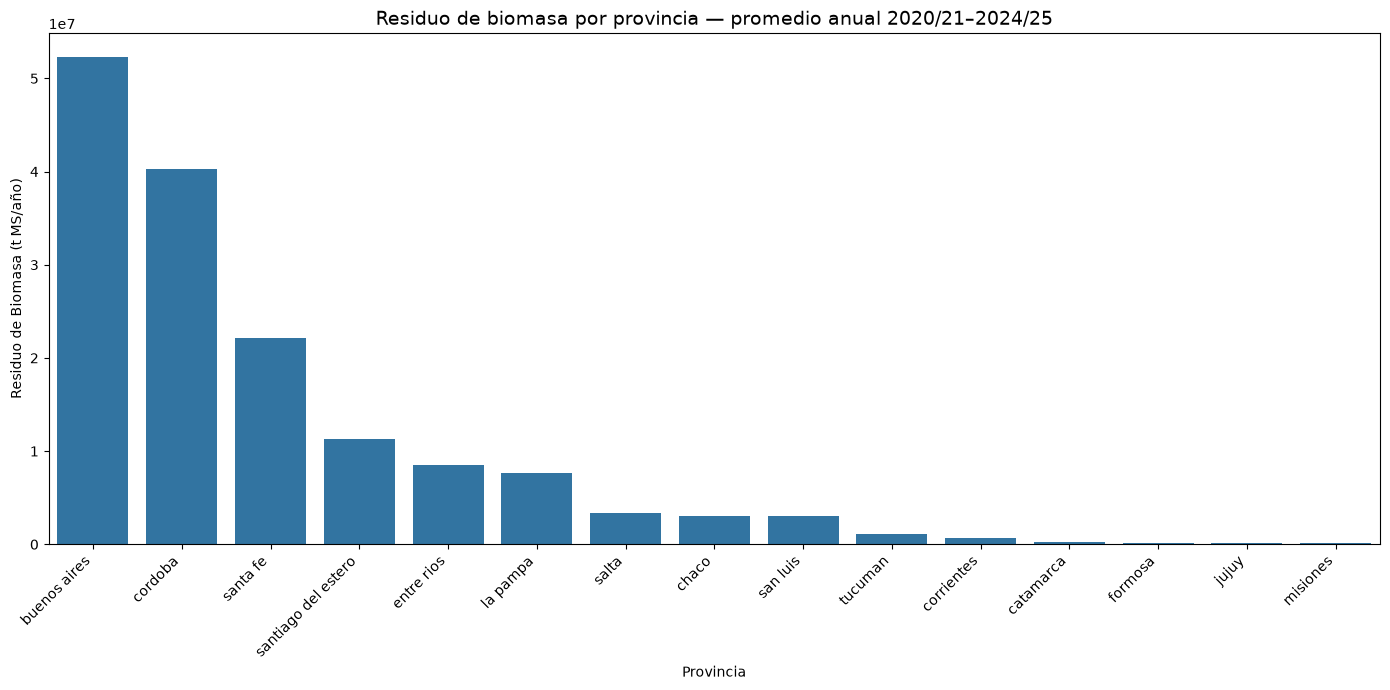

In [26]:
df_by_prov = (
    df_anual
    .groupby("Provincia", as_index=False)[["Residuo de Biomasa (Tn)", "Produccion (Tn)"]]
    .sum()
    .sort_values("Residuo de Biomasa (Tn)", ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(data=df_by_prov, x="Provincia", y="Residuo de Biomasa (Tn)",
            order=df_by_prov["Provincia"])
plt.xticks(rotation=45, ha="right")
plt.title(f"Residuo de biomasa por provincia — promedio anual {CAMPANAS_REF[0]}–{CAMPANAS_REF[-1]}", fontsize=14)
plt.ylabel("Residuo de Biomasa (t MS/año)")
plt.tight_layout()
plt.show()

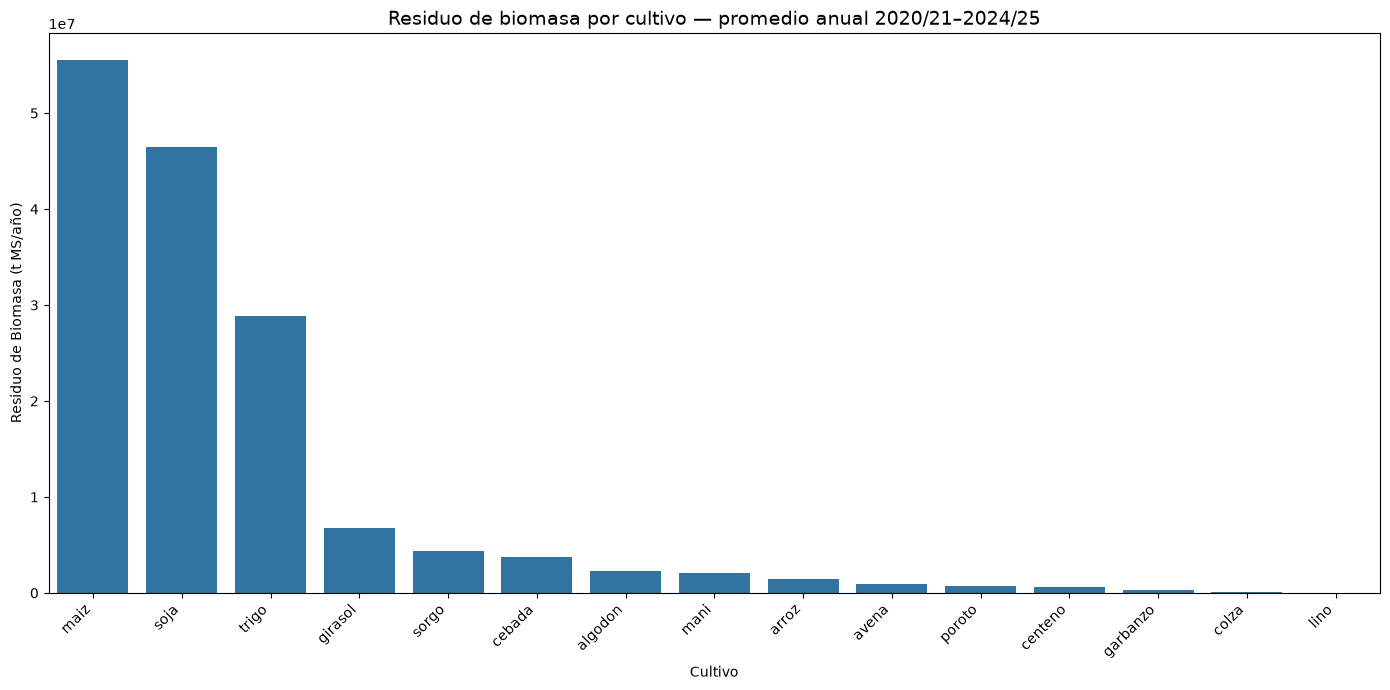

In [27]:
df_by_cultivo = (
    df_anual
    .groupby("Cultivo", as_index=False)["Residuo de Biomasa (Tn)"]
    .sum()
    .sort_values("Residuo de Biomasa (Tn)", ascending=False)
)

plt.figure(figsize=(14, 7))
sns.barplot(data=df_by_cultivo, x="Cultivo", y="Residuo de Biomasa (Tn)",
            order=df_by_cultivo["Cultivo"])
plt.xticks(rotation=45, ha="right")
plt.title(f"Residuo de biomasa por cultivo — promedio anual {CAMPANAS_REF[0]}–{CAMPANAS_REF[-1]}", fontsize=14)
plt.ylabel("Residuo de Biomasa (t MS/año)")
plt.tight_layout()
plt.show()

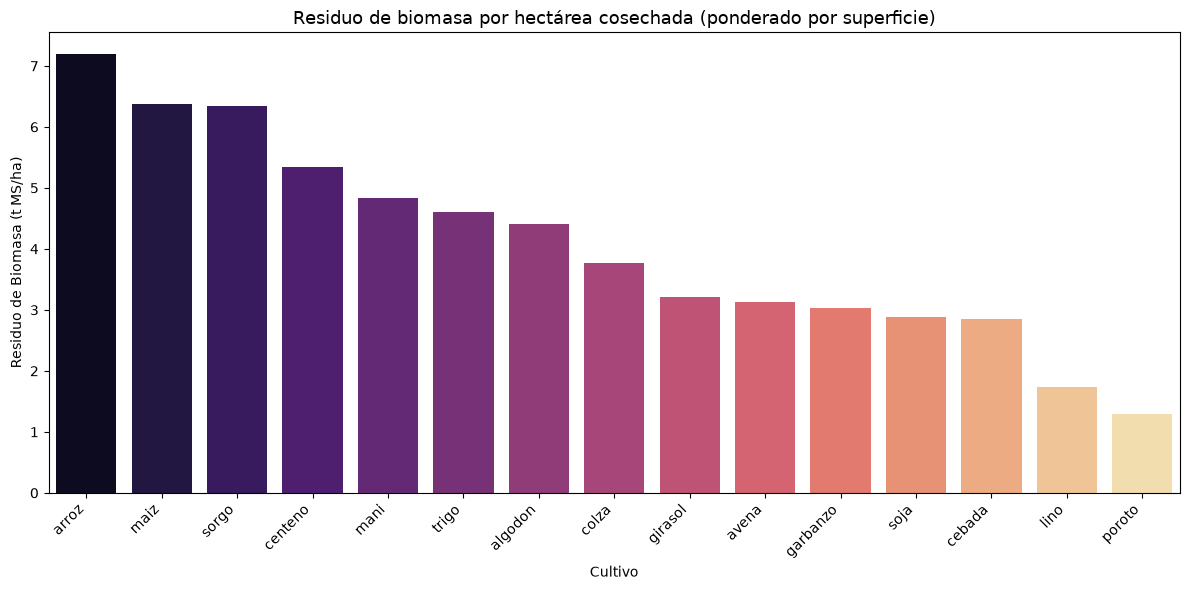

In [28]:
# Promedio ponderado por superficie: Σ residuo / Σ superficie (no promedio de cocientes).
df_efficiency = (
    df_anual.groupby("Cultivo")[["Residuo de Biomasa (Tn)", "Superficie (Ha)"]].sum()
    .assign(**{"Residuo de Biomasa (Tn/Ha)": lambda d: d["Residuo de Biomasa (Tn)"] / d["Superficie (Ha)"]})
    .reset_index()
    .sort_values("Residuo de Biomasa (Tn/Ha)", ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(data=df_efficiency, x="Cultivo", y="Residuo de Biomasa (Tn/Ha)",
            hue="Cultivo", palette="magma", legend=False, order=df_efficiency["Cultivo"])
plt.xticks(rotation=45, ha="right")
plt.title("Residuo de biomasa por hectárea cosechada (ponderado por superficie)", fontsize=13)
plt.ylabel("Residuo de Biomasa (t MS/ha)")
plt.tight_layout()
plt.show()

### Top 30 departamento-cultivo por residuo de biomasa (promedio anual)

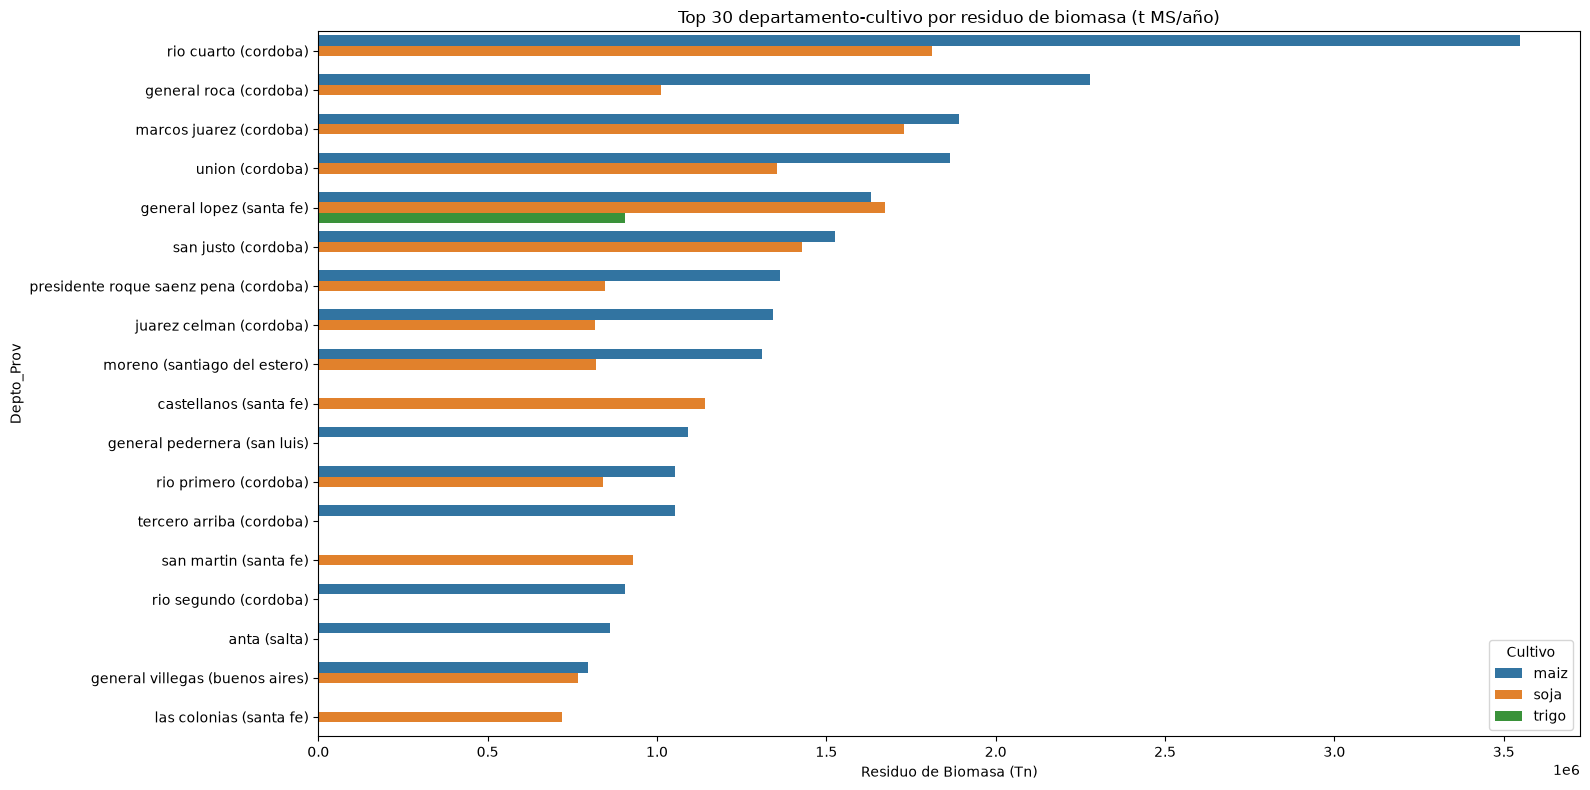

In [29]:
df_plot = (
    df_anual
    .groupby(["Provincia", "Departamento", "Cultivo"], as_index=False)
    ["Residuo de Biomasa (Tn)"]
    .sum()
)

df_plot["Depto_Prov"] = (
    df_plot["Departamento"] +
    " (" +
    df_plot["Provincia"] +
    ")"
)

top30 = df_plot.nlargest(30, "Residuo de Biomasa (Tn)")

plt.figure(figsize=(16, 8))

sns.barplot(
    data=top30,
    x="Residuo de Biomasa (Tn)",
    y="Depto_Prov",
    hue="Cultivo"
)

plt.title("Top 30 departamento-cultivo por residuo de biomasa (t MS/año)")
plt.tight_layout()
plt.show()

# Fase 5 — Conversión de biomasa residual a energía

En esta fase se transforma el residuo anual (t MS/año) en energía eléctrica generable con un gasificador **All Power Labs PP30** (25 kW eléctricos). Los parámetros operativos se leen del JSON de referencia de tarifas (`data/reference/YYYYMMDDHHMMSS_tarifas.json`, bloque `parametros_pp30`), el mismo que usa el ETL, para que notebook y pipeline den el mismo resultado.

La cadena de cálculo es:

| Paso | Fórmula | Justificación |
|---|---|---|
| 1. Residuo recuperable | $R_{rec} = R \times f_{rec}$ | Debe quedar rastrojo en el lote para cobertura de suelo y materia orgánica (A13). |
| 2. Masa seca | $m_{s} = R_{rec} \times 1000$ (kg) | Conversión de unidades. |
| 3. Masa alimentada | $m_{a} = m_{s} / (1 - H)$ | El gasificador se alimenta con biomasa a humedad operativa $H$ (≈12 %, máx. 20 %). |
| 4. Energía eléctrica | $E = m_{a} / CE$ (kWh) | $CE$ = consumo específico del PP30 ≈ 1,1 kg de biomasa *tal cual* por kWh. |
| 5. Horas de operación | $h = E / P_{nom}$ | $P_{nom}$ = 25 kW. |
| 6. Equipos equivalentes | $n = h / (8760 \times D)$ | $D$ = disponibilidad anual (0,8 ≈ 7.000 h/año). |

**Corrección metodológica**: la versión anterior hacía $E = R \times (1-H) / CE$, es decir, **restaba la humedad a una masa que ya era seca** y luego dividía por un consumo específico expresado sobre biomasa húmeda: la humedad se descontaba dos veces y se subestimaba la energía ≈ 23 %. Además usaba el 100 % del residuo.

In [30]:
from etl.transformers.energy_finance import load_tarifas_config

TARIFAS = load_tarifas_config(DATA / "reference")
P = TARIFAS["parametros_pp30"]

FRACCION_RECUPERABLE = P.get("fraccion_recuperable_default", 0.5)
HUMEDAD_PCT = P["humedad_pct_default"]
CE_KG_KWH = P["consumo_especifico_kg_kwh"]
P_NOM_KW = P["potencia_nominal_kw"]
DISPONIBILIDAD = P.get("disponibilidad", 0.8)
ALFA_AUTOCONSUMO = P["factor_autoconsumo_default"]

pd.Series({
    "Fracción recuperable del residuo": FRACCION_RECUPERABLE,
    "Humedad operativa (%)": HUMEDAD_PCT,
    "Consumo específico PP30 (kg/kWh)": CE_KG_KWH,
    "Potencia nominal PP30 (kW)": P_NOM_KW,
    "Disponibilidad anual": DISPONIBILIDAD,
    "Fracción de autoconsumo α": ALFA_AUTOCONSUMO,
}, name="valor").to_frame()

,valor
Fracción recuperable del residuo,0.5
Humedad operativa (%),12.0
Consumo específico PP30 (kg/kWh),1.1
Potencia nominal PP30 (kW),25.0
Disponibilidad anual,0.8
Fracción de autoconsumo α,0.6


## 5.1 Energía generable por registro (promedio anual)

Se aplica la cadena de cálculo al dataset anualizado. Se muestran además los kWh **por tonelada de residuo seco**, que es el rendimiento energético implícito del proceso ($1000 / ((1-H) \cdot CE)$ ≈ 1.033 kWh/t MS).

In [31]:
df_energia = df_anual.copy()
df_energia["Residuo Recuperable (Tn)"] = df_energia["Residuo de Biomasa (Tn)"] * FRACCION_RECUPERABLE
df_energia["masa_seca_kg"] = df_energia["Residuo Recuperable (Tn)"] * 1000
df_energia["masa_alimentada_kg"] = df_energia["masa_seca_kg"] / (1 - HUMEDAD_PCT / 100)
df_energia["kwh_generados"] = df_energia["masa_alimentada_kg"] / CE_KG_KWH
df_energia["horas_operacion_estimadas"] = df_energia["kwh_generados"] / P_NOM_KW
df_energia["equipos_pp30_equivalentes"] = df_energia["horas_operacion_estimadas"] / (8760 * DISPONIBILIDAD)

kwh_por_t = 1000 / ((1 - HUMEDAD_PCT / 100) * CE_KG_KWH)
print(f"Rendimiento energético implícito: {kwh_por_t:,.0f} kWh por t MS de residuo recuperable")
print(f"Residuo recuperable: {df_energia['Residuo Recuperable (Tn)'].sum():,.0f} t MS/año")
print(f"Energía generable:   {df_energia['kwh_generados'].sum() / 1e9:,.2f} TWh/año")
print(f"Equipos PP30 equivalentes (operación continua): {df_energia['equipos_pp30_equivalentes'].sum():,.0f}")

# Verificación: el notebook replica exactamente el módulo del ETL
from etl.transformers.energy_finance import compute_energy_metrics
chk = compute_energy_metrics(df_energia[["Residuo Recuperable (Tn)"]], config=TARIFAS)
assert np.allclose(chk["kwh_generados"], df_energia["kwh_generados"], equal_nan=True)
print("✓ Cálculo energético idéntico al de etl/transformers/energy_finance.py")

Rendimiento energético implícito: 1,033 kWh por t MS de residuo recuperable
Residuo recuperable: 77,094,546 t MS/año
Energía generable:   79.64 TWh/año
Equipos PP30 equivalentes (operación continua): 454,584
✓ Cálculo energético idéntico al de etl/transformers/energy_finance.py


## 5.2 Energía por provincia y por cultivo

Se agrega la energía anual por provincia y por cultivo. Como referencia de escala: la demanda eléctrica total de Argentina es del orden de 140 TWh/año. El valor obtenido es un **potencial técnico** (residuo recuperable completamente gasificado), no un potencial económico ni logístico.

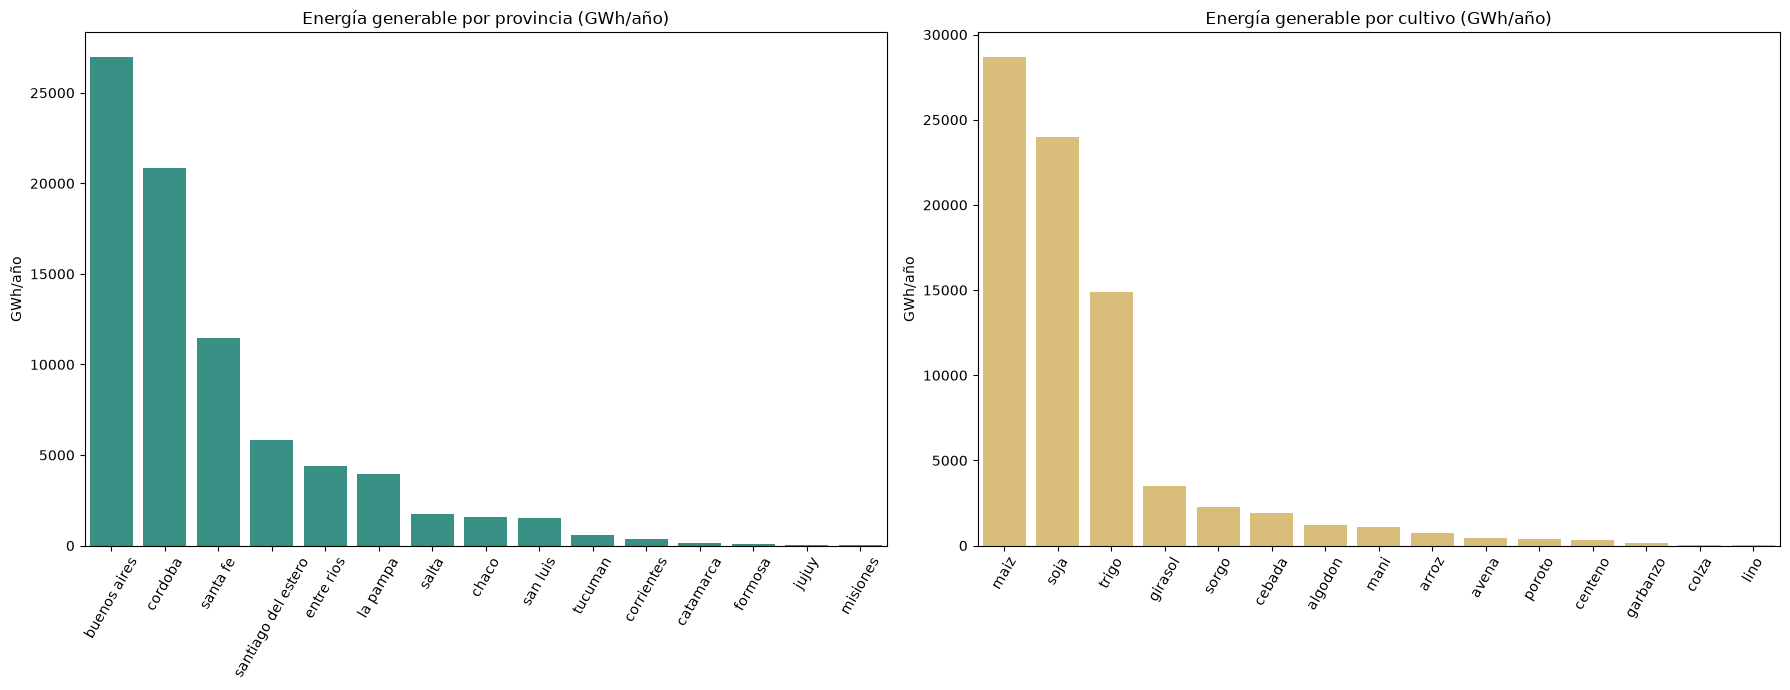

,GWh/año,% del total
Provincia,,
buenos aires,26988.8,33.9
cordoba,20822.0,26.1
santa fe,11440.7,14.4
santiago del estero,5825.1,7.3
entre rios,4413.4,5.5
la pampa,3952.9,5.0
salta,1758.4,2.2
chaco,1578.7,2.0
san luis,1548.5,1.9


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

e_prov = (df_energia.groupby("Provincia")["kwh_generados"].sum() / 1e6).sort_values(ascending=False)
sns.barplot(x=e_prov.index, y=e_prov.values, ax=axes[0], color="#2a9d8f")
axes[0].set_title("Energía generable por provincia (GWh/año)")
axes[0].set_ylabel("GWh/año")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=60)

e_cult = (df_energia.groupby("Cultivo")["kwh_generados"].sum() / 1e6).sort_values(ascending=False)
sns.barplot(x=e_cult.index, y=e_cult.values, ax=axes[1], color="#e9c46a")
axes[1].set_title("Energía generable por cultivo (GWh/año)")
axes[1].set_ylabel("GWh/año")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

(e_prov.to_frame("GWh/año").assign(**{"% del total": lambda d: 100 * d["GWh/año"] / d["GWh/año"].sum()})
 .round(1).head(10))

## 5.3 Sensibilidad de la energía a los supuestos

Los tres parámetros con mayor incertidumbre son la fracción recuperable, la humedad operativa y el consumo específico. Se muestra cómo varía la energía total al moverlos uno a la vez respecto del caso base (la relación es lineal en $f_{rec}$ e inversamente proporcional a $(1-H)$ y a $CE$).

In [33]:
R_total = df_energia["Residuo de Biomasa (Tn)"].sum()

def energia_twh(f_rec=FRACCION_RECUPERABLE, h=HUMEDAD_PCT, ce=CE_KG_KWH):
    return R_total * f_rec * 1000 / (1 - h / 100) / ce / 1e9

base = energia_twh()
sens = pd.DataFrame(
    [("Fracción recuperable", v, energia_twh(f_rec=v)) for v in (0.3, 0.4, 0.5, 0.6)]
    + [("Humedad operativa (%)", v, energia_twh(h=v)) for v in (8, 12, 15, 20)]
    + [("Consumo específico (kg/kWh)", v, energia_twh(ce=v)) for v in (1.0, 1.1, 1.2, 1.3)],
    columns=["Parámetro", "Valor", "TWh/año"],
)
sens["Δ vs base (%)"] = (100 * (sens["TWh/año"] / base - 1)).round(1)
sens.round(2)

,Parámetro,Valor,TWh/año,Δ vs base (%)
0,Fracción recuperable,0.3,47.79,-40.0
1,Fracción recuperable,0.4,63.71,-20.0
2,Fracción recuperable,0.5,79.64,0.0
3,Fracción recuperable,0.6,95.57,20.0
4,Humedad operativa (%),8.0,76.18,-4.3
5,Humedad operativa (%),12.0,79.64,0.0
6,Humedad operativa (%),15.0,82.45,3.5
7,Humedad operativa (%),20.0,87.61,10.0
8,Consumo específico (kg/kWh),1.0,87.61,10.0
9,Consumo específico (kg/kWh),1.1,79.64,0.0


# Fase 6 — Valorización económica (cálculo de dinero)

La energía generada se valoriza bajo el esquema de **balance neto de facturación** de la Ley 27.424 (generación distribuida):

- Una fracción $\alpha$ se **autoconsume** en el establecimiento y evita comprar energía a la distribuidora: se valoriza a la **tarifa de compra** (T2/T3, cargo variable de energía).
- El resto $(1-\alpha)$ se **inyecta** a la red y genera un crédito a la **tarifa de inyección** (precio de la energía para usuario-generador).

$$\text{Ahorro} = E \cdot \alpha \cdot T_{compra}, \quad \text{Crédito} = E \cdot (1-\alpha) \cdot T_{inyección}, \quad \text{Beneficio bruto} = \text{Ahorro} + \text{Crédito}$$

**Fuente de las tarifas.** El extractor `etl/extractors/scrape_tarifas.py` recorre las **28 distribuidoras** del registro `etl/reference/distribuidoras.py` (todas las provincias). Para cada una prueba primero el portal de la Secretaría de Energía (cuadros mensuales uniformes desde 2025) y luego la fuente propia de la distribuidora o del ente regulador (OCEBA, EPRE, etc.). Lee PDF, XLSX y ZIP, toma el cuadro de **vigencia más reciente** y registra cada documento procesado en el historial `data/reference/tarifas_historial.csv`.

Cada valor indica su **origen** (`estado_campos`):

| Origen | Significado |
|---|---|
| `extraido` | Extraído en esta corrida de un cuadro tarifario oficial. |
| `fallback_previous` | Extraído en una corrida anterior; hoy no se pudo descargar/validar. |
| `baseline_manual` | Valor cargado a mano en versiones previas, **no verificado**. |
| `sin_dato` | Nunca se pudo extraer: los montos de esa distribuidora quedan en NaN. |

In [34]:
tabla_tarifas = pd.DataFrame([
    {
        "distribuidora": code,
        "jurisdiccion": d.get("jurisdiccion"),
        "tarifa_compra_ARS_kWh": d.get("tarifa_compra_kwh"),
        "tarifa_inyeccion_ARS_kWh": d.get("tarifa_inyeccion_kwh"),
        "origen_compra": d.get("estado_campos", {}).get("tarifa_compra_kwh", "desconocido"),
        "vigencia": d.get("vigencia", "—"),
        "fuente": d.get("fuente_tipo", "—"),
        "documento": d.get("documento", "—"),
    }
    for code, d in TARIFAS["distribuidoras"].items()
])
print("Tarifas generadas en:", TARIFAS.get("generado_en"))
print("Resumen de extracción:", TARIFAS.get("resumen_extraccion"))
if (tabla_tarifas["origen_compra"] != "extraido").any():
    print("⚠ Hay distribuidoras sin tarifa extraída del cuadro vigente: sus montos son NaN o ilustrativos (baseline).")
tabla_tarifas

Tarifas generadas en: 2026-10-04T21:49:15
Resumen de extracción: {'distribuidoras_totales': 28, 'extraidas_en_esta_corrida': 19, 'fallback_previous': 1, 'baseline_manual': 0, 'sin_dato': 8}
⚠ Hay distribuidoras sin tarifa extraída del cuadro vigente: sus montos son NaN o ilustrativos (baseline).


,distribuidora,jurisdiccion,tarifa_compra_ARS_kWh,tarifa_inyeccion_ARS_kWh,origen_compra,vigencia,fuente,documento
0,EDENOR,CABA (norte) y GBA norte/oeste,108.36900,NaN,extraido,2026-06,nacional,http://www.energia.gob.ar/contenidos/archivos/...
1,EDESUR,CABA (sur) y GBA sur,107.91000,NaN,extraido,2026-05,nacional,http://www.energia.gob.ar/contenidos/archivos/...
2,EDELAP,Buenos Aires (Gran La Plata),148.72380,NaN,extraido,2026-09,propia,https://oceba.gba.gov.ar/nueva_web/adjuntos/ct...
3,EDEA,Buenos Aires (Costa Atlántica),136.43930,NaN,extraido,2026-09,propia,https://oceba.gba.gov.ar/nueva_web/adjuntos/ct...
4,EDEN,Buenos Aires (norte y centro),135.23410,NaN,extraido,2026-09,propia,https://oceba.gba.gov.ar/nueva_web/adjuntos/ct...
5,EDES,Buenos Aires (sur),137.18140,NaN,extraido,2026-09,propia,https://oceba.gba.gov.ar/nueva_web/adjuntos/ct...
6,ECSAPEM,Catamarca,106.28844,NaN,extraido,2026-05,nacional,http://www.energia.gob.ar/contenidos/archivos/...
7,SECHEEP,Chaco,117.49885,89.9911,extraido,2026-06,nacional,http://www.energia.gob.ar/contenidos/archivos/...
8,EPEC,Córdoba,NaN,NaN,sin_dato,—,—,—
9,DPEC,Corrientes,109.20400,NaN,extraido,2026-04,nacional,http://www.energia.gob.ar/contenidos/archivos/...


## 6.1 Asignación de distribuidora y cálculo por registro

La tarifa de cada registro se resuelve con `TariffResolver` (el mismo objeto que usa el ETL), en este orden:

1. **Excepción por departamento**, para áreas de concesión bien delimitadas: zona este de Mendoza → EDESTE (San Martín, Junín, Rivadavia, Santa Rosa, La Paz); Gran La Plata → EDELAP.
2. **Distribuidora de la provincia**. Si la provincia tiene varias (interior bonaerense: EDEN, EDEA, EDES), se usa el **promedio** de las que tienen tarifa y el registro se marca como aproximado (`tarifa_es_proxy = True`). También se marca APE (La Pampa), donde gran parte del servicio lo prestan cooperativas.
3. **Chubut** no tiene distribuidora provincial única (cooperativas): queda sin tarifa.

La columna `tarifa_origen` permite filtrar los montos que provienen sólo de tarifas reales (`SOLO_TARIFAS_EXTRAIDAS = True`).

Los montos están en **ARS corrientes del mes de vigencia de cada cuadro** y corresponden a un año típico del período de referencia.

In [35]:
from etl.transformers.energy_finance import TariffResolver, add_energy_finance_columns

SOLO_TARIFAS_EXTRAIDAS = False  # True: excluye tarifas baseline_manual

resolver = TariffResolver(TARIFAS)
res = [resolver.resolve(p, d) for p, d in zip(df_energia["Provincia"], df_energia["Departamento"])]

df_dinero = df_energia.copy()
df_dinero["distribuidora"] = [r["distribuidora"] for r in res]
df_dinero["tarifa_compra_kwh"] = [r["compra"] for r in res]
df_dinero["tarifa_inyeccion_kwh"] = [r["inyeccion"] for r in res]
df_dinero["tarifa_es_proxy"] = [r["es_proxy"] for r in res]
df_dinero["tarifa_origen"] = [r["origen"] for r in res]
if SOLO_TARIFAS_EXTRAIDAS:
    real = df_dinero["tarifa_origen"].str.fullmatch(r"(extraido|fallback_previous)(\+(extraido|fallback_previous))*")
    df_dinero.loc[~real, ["tarifa_compra_kwh", "tarifa_inyeccion_kwh"]] = np.nan

df_dinero["kwh_autoconsumo"] = df_dinero["kwh_generados"] * ALFA_AUTOCONSUMO
df_dinero["kwh_inyectados"] = df_dinero["kwh_generados"] * (1 - ALFA_AUTOCONSUMO)
df_dinero["ahorro_autoconsumo_ars"] = df_dinero["kwh_autoconsumo"] * df_dinero["tarifa_compra_kwh"]
df_dinero["credito_inyeccion_ars"] = df_dinero["kwh_inyectados"] * df_dinero["tarifa_inyeccion_kwh"]
df_dinero["beneficio_total_ars"] = df_dinero["ahorro_autoconsumo_ars"] + df_dinero["credito_inyeccion_ars"]

# Verificación contra el módulo del ETL
if not SOLO_TARIFAS_EXTRAIDAS:
    chk = add_energy_finance_columns(
        df_anual.assign(**{"Residuo Recuperable (Tn)": df_energia["Residuo Recuperable (Tn)"]}),
        config=TARIFAS,
    )
    assert np.allclose(chk["beneficio_total_ars"], df_dinero["beneficio_total_ars"], equal_nan=True)
    print("✓ Cálculo financiero idéntico al de etl/transformers/energy_finance.py")

con_tarifa = df_dinero["tarifa_compra_kwh"].notna()
print(f"\nEnergía con tarifa asignada: {100 * df_dinero.loc[con_tarifa, 'kwh_generados'].sum() / df_dinero['kwh_generados'].sum():.1f} % del total")
cobertura = (
    df_dinero.groupby(["tarifa_origen"])["kwh_generados"].sum().div(df_dinero["kwh_generados"].sum()).mul(100).round(1)
    .rename("% de la energía")
)
cobertura.to_frame()

✓ Cálculo financiero idéntico al de etl/transformers/energy_finance.py

Energía con tarifa asignada: 53.7 % del total


,% de la energía
tarifa_origen,
extraido,53.6
fallback_previous,0.1
sin_dato,46.3


## 6.2 Resultado económico por provincia

Se resume por provincia la energía, el ahorro por autoconsumo, el crédito por inyección y el beneficio bruto anual, junto con el **valor medio por kWh** (beneficio / kWh) y por **tonelada de residuo recuperable**, útiles para comparar contra el costo de recolección y flete del rastrojo.

In [36]:
resumen = (
    df_dinero[con_tarifa]
    .groupby(["Provincia", "distribuidora", "tarifa_es_proxy"], as_index=False)
    [["Residuo Recuperable (Tn)", "kwh_generados", "ahorro_autoconsumo_ars",
      "credito_inyeccion_ars", "beneficio_total_ars", "equipos_pp30_equivalentes"]]
    .sum()
    .sort_values("beneficio_total_ars", ascending=False)
)
resumen["ARS/kWh medio"] = resumen["beneficio_total_ars"] / resumen["kwh_generados"]
resumen["ARS/t residuo"] = resumen["beneficio_total_ars"] / resumen["Residuo Recuperable (Tn)"]

vista = resumen.assign(
    **{
        "GWh/año": resumen["kwh_generados"] / 1e6,
        "Ahorro (MM ARS/año)": resumen["ahorro_autoconsumo_ars"] / 1e6,
        "Crédito inyección (MM ARS/año)": resumen["credito_inyeccion_ars"] / 1e6,
        "Beneficio bruto (MM ARS/año)": resumen["beneficio_total_ars"] / 1e6,
    }
)[["Provincia", "distribuidora", "tarifa_es_proxy", "GWh/año", "Ahorro (MM ARS/año)",
   "Crédito inyección (MM ARS/año)", "Beneficio bruto (MM ARS/año)", "ARS/kWh medio",
   "ARS/t residuo", "equipos_pp30_equivalentes"]]
print(f"Beneficio bruto total (provincias con tarifa): {resumen['beneficio_total_ars'].sum() / 1e9:,.1f} mil MM ARS/año")
vista.round(1)

Beneficio bruto total (provincias con tarifa): 679.7 mil MM ARS/año


,Provincia,distribuidora,tarifa_es_proxy,GWh/año,Ahorro (MM ARS/año),Crédito inyección (MM ARS/año),Beneficio bruto (MM ARS/año),ARS/kWh medio,ARS/t residuo,equipos_pp30_equivalentes
5,entre rios,ENERSA,False,4413.4,346471.1,165150.2,511621.3,115.9,119756.2,25190.8
3,chaco,SECHEEP,False,1578.7,111294.1,56826.0,168120.1,106.5,110016.3,9010.6
0,buenos aires,EDELAP,False,37.4,3338.3,0.0,0.0,0.0,0.0,213.5
2,catamarca,ECSAPEM,False,149.1,9507.4,0.0,0.0,0.0,0.0,850.9
1,buenos aires,EDEN+EDEA+EDES,True,26951.4,2203843.8,0.0,0.0,0.0,0.0,153832.3
4,corrientes,DPEC,False,365.9,23976.6,0.0,0.0,0.0,0.0,2088.6
6,formosa,REFSA,False,93.7,7608.8,0.0,0.0,0.0,0.0,535.0
7,jujuy,EJESA,False,60.2,4082.3,0.0,0.0,0.0,0.0,343.4
8,salta,EDESA,False,1758.4,281501.2,0.0,0.0,0.0,0.0,10036.8
9,san luis,EDESAL,False,1548.5,102906.7,0.0,0.0,0.0,0.0,8838.6


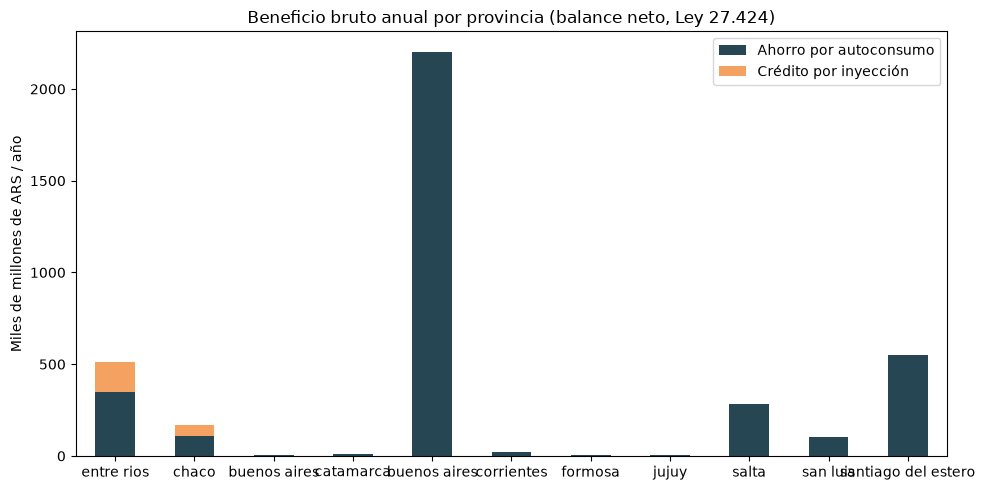

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = resumen.set_index("Provincia")[["ahorro_autoconsumo_ars", "credito_inyeccion_ars"]] / 1e9
plot_df.columns = ["Ahorro por autoconsumo", "Crédito por inyección"]
plot_df.plot(kind="bar", stacked=True, ax=ax, color=["#264653", "#f4a261"])
ax.set_ylabel("Miles de millones de ARS / año")
ax.set_xlabel("")
ax.set_title("Beneficio bruto anual por provincia (balance neto, Ley 27.424)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 6.3 Top 15 departamentos por beneficio bruto

El análisis departamental permite identificar dónde se concentra el residuo y, por lo tanto, dónde una planta (o un grupo de equipos PP30) tendría menor costo logístico de abastecimiento.

In [38]:
top_dep = (
    df_dinero[con_tarifa]
    .groupby(["Provincia", "Departamento"], as_index=False)
    [["Residuo Recuperable (Tn)", "kwh_generados", "beneficio_total_ars", "equipos_pp30_equivalentes"]]
    .sum()
    .nlargest(15, "beneficio_total_ars")
)
top_dep.assign(
    **{"GWh/año": top_dep["kwh_generados"] / 1e6,
       "Beneficio bruto (MM ARS/año)": top_dep["beneficio_total_ars"] / 1e6}
)[["Provincia", "Departamento", "Residuo Recuperable (Tn)", "GWh/año",
   "Beneficio bruto (MM ARS/año)", "equipos_pp30_equivalentes"]].round(1)

,Provincia,Departamento,Residuo Recuperable (Tn),GWh/año,Beneficio bruto (MM ARS/año),equipos_pp30_equivalentes
162,entre rios,gualeguaychu,556233.1,574.6,66612.4,3279.8
165,entre rios,parana,518413.3,535.6,62083.2,3056.8
170,entre rios,villaguay,432950.5,447.3,51848.5,2552.9
163,entre rios,la paz,423756.8,437.8,50747.5,2498.7
164,entre rios,nogoya,382540.9,395.2,45811.6,2255.6
168,entre rios,uruguay,368148.8,380.3,44088.1,2170.8
169,entre rios,victoria,321516.4,332.1,38503.6,1895.8
161,entre rios,gualeguay,294486.9,304.2,35266.6,1736.4
115,chaco,almirante brown,302126.4,312.1,33238.8,1781.5
157,entre rios,diamante,254211.2,262.6,30443.4,1498.9


## 6.4 Sensibilidad del beneficio a la fracción de autoconsumo

Como la tarifa de compra es mayor que la de inyección, el beneficio crece con la fracción autoconsumida $\alpha$. En la práctica $\alpha$ está acotada por la demanda propia del establecimiento (un PP30 genera ≈ 175 MWh/año con 7.000 h de operación).

In [39]:
kwh_ct = df_dinero.loc[con_tarifa, "kwh_generados"]
t_c = df_dinero.loc[con_tarifa, "tarifa_compra_kwh"]
t_i = df_dinero.loc[con_tarifa, "tarifa_inyeccion_kwh"]
sens_alfa = pd.DataFrame({
    "α autoconsumo": [0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
})
sens_alfa["Beneficio bruto (mil MM ARS/año)"] = [
    ((kwh_ct * a * t_c) + (kwh_ct * (1 - a) * t_i)).sum() / 1e9 for a in sens_alfa["α autoconsumo"]
]
sens_alfa.round(1)

,α autoconsumo,Beneficio bruto (mil MM ARS/año)
0,0.0,554.9
1,0.2,596.5
2,0.4,638.1
3,0.6,679.7
4,0.8,721.3
5,1.0,762.9


## 6.5 Alcance de los montos

- Son **beneficios brutos**: no descuentan CAPEX del gasificador, operación y mantenimiento, ni el costo de recolección, enfardado y flete del rastrojo. Para una evaluación de factibilidad debe compararse `ARS/t residuo` contra esos costos.
- Las tarifas son **sin impuestos** y de un único mes; no se proyecta su evolución.
- Las distribuidoras sin tarifa extraída (`sin_dato`) no se valorizan (NaN, no se imputan); Chubut no tiene distribuidora provincial.
- Los montos con origen `baseline_manual` son ilustrativos (valores no verificados); usar `SOLO_TARIFAS_EXTRAIDAS = True` para excluirlos.
- En el interior bonaerense la tarifa es el promedio de EDEN/EDEA/EDES; las ~200 cooperativas tienen cuadros propios (OCEBA).

## 6.6 Historial de tarifas

Cada corrida del extractor agrega al historial `data/reference/tarifas_historial.csv` los cuadros procesados (uno por documento, deduplicado por huella SHA-256), con su **vigencia**, los valores extraídos y el documento de origen. Para reconstruir la serie completa desde enero de 2025 a partir del portal nacional:

```bash
python -m etl.extractors.scrape_tarifas --historial --desde 2025-01
```

La serie permite ver la evolución nominal de cada tarifa y, en análisis futuros, valorizar cada campaña con la tarifa vigente en su momento (o deflactar a moneda constante).

Documentos en el historial: 850 | distribuidoras: 20


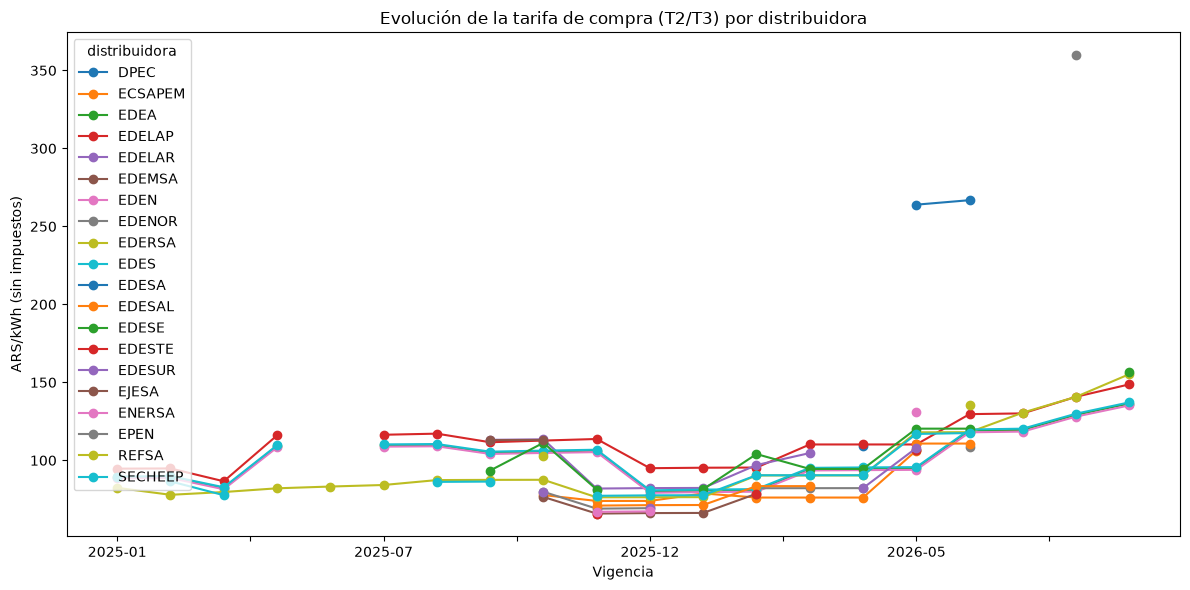

distribuidora,DPEC,ECSAPEM,EDEA,EDELAP,EDELAR,EDEMSA,EDEN,EDENOR,EDERSA,EDES,EDESA,EDESAL,EDESE,EDESTE,EDESUR,EJESA,ENERSA,EPEN,REFSA,SECHEEP
vigencia,,,,,,,,,,,,,,,,,,,,
2025-10,NaN,77.74,105.66,112.68,113.46,76.52,104.74,79.84,87.53,106.24,NaN,NaN,111.24,NaN,79.93,113.09,NaN,NaN,103.03,NaN
2025-11,NaN,73.97,106.21,113.69,81.91,65.86,105.28,69.02,76.30,106.81,NaN,70.98,81.28,65.86,NaN,NaN,67.00,NaN,NaN,77.26
2025-12,NaN,73.97,80.04,94.96,82.20,66.19,79.20,69.34,76.35,80.78,NaN,71.27,NaN,NaN,69.49,NaN,67.28,NaN,NaN,77.55
2026-01,NaN,78.79,80.48,95.27,82.30,66.28,79.63,NaN,76.41,81.23,NaN,71.37,81.49,NaN,NaN,NaN,NaN,NaN,NaN,77.65
2026-02,NaN,76.14,80.78,95.37,96.98,78.59,79.91,82.12,90.32,81.55,NaN,83.46,104.03,78.59,NaN,NaN,NaN,NaN,NaN,90.44
2026-03,NaN,76.14,94.45,110.18,104.67,NaN,93.51,82.15,90.32,95.19,NaN,83.46,94.49,NaN,NaN,NaN,NaN,NaN,NaN,90.44
2026-04,109.2,76.14,94.68,110.18,NaN,NaN,93.73,82.18,90.35,95.44,NaN,NaN,94.49,NaN,82.20,NaN,NaN,NaN,NaN,90.44
2026-05,NaN,106.29,94.87,110.18,NaN,106.51,93.91,NaN,117.97,95.65,263.93,110.76,120.32,106.51,107.91,NaN,130.84,NaN,NaN,116.93
2026-06,NaN,NaN,119.05,129.63,NaN,NaN,117.97,108.37,118.05,119.77,266.81,110.76,120.32,NaN,NaN,NaN,NaN,NaN,135.28,117.50


In [40]:
from etl.loaders.tariff_history import load_history, tariff_series

historial = load_history(DATA / "reference")
print(f"Documentos en el historial: {len(historial)} | distribuidoras: {historial['distribuidora'].nunique()}")
if historial.empty:
    print("El historial está vacío: correr el extractor con acceso a internet "
          "(python -m etl.extractors.scrape_tarifas --historial).")
else:
    serie = tariff_series(historial, "tarifa_compra_kwh")
    ax = serie.plot(figsize=(12, 6), marker="o")
    ax.set_title("Evolución de la tarifa de compra (T2/T3) por distribuidora")
    ax.set_ylabel("ARS/kWh (sin impuestos)")
    ax.set_xlabel("Vigencia")
    plt.tight_layout()
    plt.show()
    display(serie.tail(12).round(2))

# Fase 7 — Persistencia de resultados

Se persisten el dataset curado, el potencial energético-económico anual y los artefactos de auditoría para permitir reproducción y análisis posterior.

In [41]:
audit_dir = DATA / "audit"
audit_dir.mkdir(parents=True, exist_ok=True)
processed_dir = DATA / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

audit = cmp.copy()
audit.columns = ["__".join(map(str, c)) for c in audit.columns]  # parquet requiere nombres str
audit.reset_index().to_parquet(audit_dir / "discrepancias_cba_vs_magyp_notebook.parquet")
df_descartado.to_parquet(audit_dir / "descartados_reconciliacion_notebook.parquet")
df_dinero.to_parquet(processed_dir / "potencial_energetico_anual_notebook.parquet")

print("Artefactos persistidos en", audit_dir, "y", processed_dir)

Artefactos persistidos en /home/user/SYNGAS-OPTIMIA-HV/data/audit y /home/user/SYNGAS-OPTIMIA-HV/data/processed


# Síntesis de hallazgos y limitaciones

## Acciones implementadas y su impacto medido

| Acción | Hallazgo | Impacto medido |
|--------|----------|----------------|
| A1 — Normalización léxica | H2 | Reducción del dominio de cultivos a nombres canónicos unificados. |
| A2 — Taxonomía | H3 | Cultivos canónicos definidos con marca de agregado (incluye `alfalfa` de CBA). |
| A3 — Normalización geográfica | H4 | Provincias y departamentos unificados entre fuentes. |
| A4 — Resolución agregados | H3 | Eliminación de doble conteo interno por fuente. |
| A5 — Reconciliación multi-fuente | H1 | Prioridad por producción, con desempate determinístico a favor de MAGYP. |
| A6 — Limpieza CBA | H5 | Eliminación de columnas con cobertura 5 %. |
| A7 — Conversión numérica | H6 | Reporte de valores coercidos por columna. |
| A8 — Flags de validez | H7 | Cobertura cuantificada; válido exige IC, superficie > 0 y residuo finito. |
| A9 — Deduplicación CBA | H8 | Eliminadas las filas replicadas por el merge cartesiano. |
| A10 — `sum(min_count=1)` | H9 | Los faltantes no se convierten en producción 0. |
| A11 — Período de referencia | H10 | Resultados anuales (promedio de 5 campañas completas). |
| A12 — Base seca | H11 | Residuo corregido por materia seca del producto cosechado. |
| A13 — Fracción recuperable | H12 | Energía calculada sobre el residuo retirable del lote. |

## Limitaciones metodológicas reconocidas

1. **Cobertura geográfica asimétrica**: MAGYP cubre 23 provincias; CBA cubre 7 y actúa como fuente complementaria cuando MAGYP no reporta.
2. **IC y MS constantes por cultivo**: sin ajuste por genética, prácticas agronómicas o variabilidad regional.
3. **Cultivos sin IC documentado excluidos**: caña de azúcar, yerba mate, cítricos y otros quedan fuera del análisis. Esto subrepresenta al NOA y NEA (sección 4.4).
4. **Reconciliación por mayor producción**: asume que la mayor magnitud declarada es la más representativa; sin validación contra *ground truth*.
5. **Fracción recuperable única (50 %)**: en la práctica depende del cultivo, la labranza (siembra directa requiere más cobertura), la pendiente y el clima.
6. **Potencial técnico, no económico**: la energía supone gasificar todo el residuo recuperable; no considera logística, estacionalidad de cosecha ni almacenamiento.
7. **Beneficio bruto con la tarifa vigente más reciente**: no incluye costos ni impuestos; las tarifas `baseline_manual` no están verificadas; en Buenos Aires y La Pampa la tarifa es una aproximación (promedio de distribuidoras / cooperativas). El historial de tarifas permite, a futuro, valorizar cada campaña con su tarifa de época.